# Visión por Computador - Práctica 1 - Introducción a OpenCV, Uso Responsable de Herramientas de IA Generativa, y Primeros Pasos con Procesado de Imagen

#### 5 puntos   |   Fecha de entrega: 18 de octubre de 2026, 23:59   |   Forma de entrega: a través de la tarea creada en https://pradogrado2627.ugr.es/

### Estudiante: <mark>Ismael Sallami Moreno</mark>



---

## Normas de desarrollo y entrega de la práctica

1. Para este trabajo, al igual que para los demás, se debe presentar código, resultados, discusión de los mismos, y presentación y análisis del trabajo realizado, todo integrado en el propio Google Colab Notebook (es decir, no se entrega ninguna memoria separada en `.pdf` ni ningún código `.py`). Se recuerda que código y resultados sin informe explicativo no puntúa. Resulta también fundamental recordar que solo se acepta la entrega de ficheros `.ipynb` (no resulta válido entregar un fichero `.py`).

2. En relación con el punto anterior, se recuerda que se proporciona un Notebook, denominado `Ejemplo_Otsu.ipynb`, que muestra un ejemplo de respuesta y solución a un potencial ejercicio. El propósito de este Notebook es servir de referencia al alumnado acerca de cómo responder los ejercicios planteados. Véase que, por ejemplo, en aras de diferenciar con facilidad enunciados y respuestas, estas últimas se presentan en otro color (azul, en ese caso).

3. El diseño de celdas del documento debe ser respetado. Es decir, no se puede modificar el orden de los ejercicios o alterar la estructura del Notebook, de forma que dificulte localizar los contenidos. Aunque sí se puede, por ejemplo, crear nuevas subsecciones dentro de las secciones ya existentes para estructurar y organizar con más claridad las respuestas, así como para incluir los experimentos extra que se deseen.

4. Tal y como se muestra en `Ejemplo_Otsu.ipynb`, no hay ningún problema en emplear técnicas de IA generativa (como ChatGPT o Gemini) para crear el código de los distintos ejercicios o para enriquecer el análisis y descripción del trabajo realizado (aunque, obvia decirlo, su uso no es obligatorio). Pero, en caso de usarse, sí se debe aclarar de qué modo se ha usado la IA, con qué objetivo, y se debe demostrar que se entiende perfectamente lo que se ha hecho.

5. Solo se entregará el fichero `.ipynb` (incorporando código, resultados, y explicación del trabajo realizado y los resultados obtenidos) y no se enviarán las imágenes empleadas. El path para la lectura de imágenes, o cualquier otro fichero de entrada, debe ser siempre “/content/drive/My Drive/images/nombre_fichero”.

6. El código deberá  presentarse adecuadamente comentado y con los resultados obtenidos en cada apartado, junto con la presentación del trabajo realizado y la discusión y análisis de los resultados obtenidos. Es importante reiterar que la entrega de código sin informe explicativo o valoraciones no puntúa. Por otro lado, el código debe ir comentado en comentarios en celdas de código, mientras que el análisis y discusión, tanto del trabajo realizado como de los resultados obtenidos, debe ir en celdas de texto.






### Materiales de Apoyo

En caso de que el alumnado tenga dudas sobre Python, OpenCV o el uso de Google Colab, se recuerda que en PRADO hay materiales de apoyo (https://pradogrado2627.ugr.es/mod/folder/view.php?id=83733):
-  Introducción a Python: https://pradogrado2627.ugr.es/pluginfile.php/153447/mod_folder/content/0/1.%20Introduccion%20a%20Python.pdf
- Introducción a NumPy, Matplotlib y Scikit-learn: https://pradogrado2627.ugr.es/pluginfile.php/153447/mod_folder/content/0/2.%20Introducci%C3%B3n%20a%20Numpy%20Matplotlib%20y%20sklearn.pdf
- Notebook con toda la información anterior (y más cosas): https://pradogrado2627.ugr.es/pluginfile.php/153447/mod_folder/content/0/Guia_Python.ipynb
- Ejercicios y ejemplos de repaso: https://pradogrado2627.ugr.es/pluginfile.php/153447/mod_folder/content/0/3.%20Ejercicios%20y%20ejemplos%20de%20repaso.pdf
- Fundamentos de Python para lectura, visualización y manipulación de imágenes: https://pradogrado2627.ugr.es/pluginfile.php/153447/mod_folder/content/0/4.%20Fundamentos%20de%20Python%20para%20manipulacion%20de%20imagenes.pdf(y Notebook asociado: https://pradogrado2627.ugr.es/pluginfile.php/153447/mod_folder/content/0/Guia_fundamentos_imagenes.ipynb)
- Ideas sobre cómo redactar un documento académico-científico (útil para saber cómo documentar las respuestas a los ejercicios, el Notebook en su conjunto, y la memoria del proyecto final o de un TFG/TFM): https://pradogrado2627.ugr.es/pluginfile.php/153447/mod_folder/content/0/Algunas%20ideas%20sobre%20c%C3%B3mo%20elaborar%20un%20informe%20acad%C3%A9mico-cient%C3%ADfico.pdf
- Ejemplo de respuesta a un hipotético ejercicio sobre el algoritmo de umbralización de Otsu: https://pradogrado2627.ugr.es/pluginfile.php/153448/mod_folder/content/0/Ejemplo_Otsu.ipynb



---



## Funciones de apoyo y conexión con Google Drive

In [1]:
# We start by getting access to the drive
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [2]:
# We import the main potential modules to use
import os,sys
import cv2, numpy as np, math
from matplotlib import pyplot as plt
# change directory
%cd '/content/drive/My Drive'
#  the current directory
%pwd

# This allows to display images  and to save  them in cells
%matplotlib inline
# this definition allows to read files in a specific path
get_image = lambda route: os.path.join('/content/drive/My Drive/images', route)

/content/drive/My Drive


Las funciones que se incluyen a continuación, se proporcionan como ayuda/apoyo para el estudiante. **En caso de que el alumnado prefiera utilizar otras funciones para lectura, normalización y visualización de imágenes, tiene total libertad para hacerlo, pero sí debe justificar y explicar razonadamente el motivo de dicho cambio y describir las modificaciones realizadas.**

Recuérdese que todas las imágenes a emplear durante las prácticas de todo el curso se pueden encontrar en el enlace de Google Drive indicado en PRADO: https://pradogrado2627.ugr.es/mod/url/view.php?id=83732 En concreto, https://drive.google.com/drive/folders/1UtvY8q6w1Cz9a9T9zxIqSweoRLgNwoW-

In [3]:
'''
This function receives a string with the filename of the image to read,
and a flag indicating if we want to read it in color/RGB (flagColor=1) or gray level (flagColor=0)

Example of use:
im1=readIm(get_image('apple.jpg'),0)

'''
def readIm(filename, flagColor=1):
  # cv2 reads BGR format
  im=cv2.imread(filename)
  if im is None:
    raise FileNotFoundError(f'No se ha podido leer la imagen: {filename}')
  # change to  RGB and return the image
  if(flagColor):
    return cv2.cvtColor(im, cv2.COLOR_BGR2RGB)
  # change from BGR to grayscale instead if flag is 0
  return cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)

In [4]:
'''
This function receives an array of arbitrary real numbers (that could include even negative values),
and returns an 'image' in the range [0,1].
flag_GLOBAL allows the user to normalize the whole image (including all channels) or to normalize
each channel/band independently.
'''
def rangeDisplay01(im, flag_GLOBAL= True):
  im = im.astype(float)
  if flag_GLOBAL:
    vmin = im.min()
    vmax = im.max()
    if vmax == vmin:
      return np.zeros_like(im, dtype=float)
    im = (im - vmin) / (vmax - vmin)
  else:
    # bands normalization
    for band in range(im.shape[2]):
      im[:, :, band] = (im[:, :, band] - im[:, :, band].min())/(im[:, :, band].max() - im[:, :, band].min())
      # Note: remember that, for plt.imshow with RGB data, the valid range is [0..1] for floats and [0..255] for integers.
  return im

In [5]:
'''
This function displays a single image, including a title, using a magnification factor.

Example of use:
im1=readIm(get_image('apple.jpg'),0)
displayIm(im1,'Manzana',0.5)

'''
def displayIm(im, title='Result',factor= 2):
  # First normalize range
  max=np.max(im)
  min=np.min(im)
  if min<0 or max>255:
    im=rangeDisplay01(im,flag_GLOBAL=True)
  if len(im.shape) == 3:
    # im es tribanda
    plt.imshow(im, cmap='jet')
  else:
    # im es monobanda
    plt.imshow(im, cmap='gray')
  figure_size = plt.gcf().get_size_inches()
  plt.gcf().set_size_inches(factor * figure_size)
  plt.title(title)
  plt.xticks([]), plt.yticks([]) # eliminamos numeración
  plt.show()

In [6]:
'''
This function displays multiple images (including a title and using a magnification factor)
of equal size. The input to the function is a list of images.

Example of use:
im1=readIm(get_image('apple.jpg'),1)
images = [im1,im1,im1]

displayMI_ES(images, title='Manzanas',factor=1)

IMPORTANT NOTE: it is important to notice that this function stacks all images
and later call displayIm(). This implies that the normalization (rangeDisplay01()) is done
at the very end of the process. As a consequence, if the stacked images have different
range values they can be displayed in a "weird" way (with black regions (pixel value = 0)
looking grey). In case the visualization seems to be a problem, a possible solution
would be to create vim using vim.append(rangeDisplay01(...)). In this way, all images
would be on the same range of values (negative values around 0 (black),
0 values around 0.5 (grey), and positive values closer to 1 (white))

'''
def displayMI_ES(vim, title='Result',factor=2):
  # We set the maximun number of images to concatenate by columns
  maxcolumns=4
  # number of images to display
  numberim=len(vim)
  # The simplest case, one row: the maximum number of columns is larger than the images to stack
  # This is, by default, we put together the images column-wise
  if len(vim) < maxcolumns:
    out=vim[0]
    for item in range(1,len(vim)):
      #displayIm(out,str(item),1)
      out=np.hstack((out,vim[item]))

  # Else, if maxcolumns is smaller or equal than the number of images to stack
  else:
    # We check if all rows and columns are going to be 'busy', or if otherwise we need an extra-row
    if np.mod(len(vim),maxcolumns)== 0:
      maxrows=numberim//maxcolumns
    else:
      maxrows=numberim//maxcolumns+1

    # we build up the first block-row
    out=vim[0]
    for item in range(1,maxcolumns):
      out=np.hstack((out,vim[item]))
    # We build up the rest of block-rows
    for block in range(1,maxrows):
      #print(block)
      row=vim[block*maxcolumns]
      for item in range(1,maxcolumns):
        # We still have images to stack
        if block*maxcolumns+item < numberim:
          row=np.hstack((row,vim[block*maxcolumns+item]))
        # We do not have more images, and we have to fill with black
        else:
          row=np.hstack((row,np.zeros(vim[0].shape,dtype=vim[0].dtype)))
          #print(row.dtype)
          # if we don't include ',dtype=vim[0].dtype', np.zeros will include float
          # numbers in the matrix. This will make that the whole matrix will be
          # considered as floats, and values larger than 1 will be clipped to 1,
          # displaying an almost totally white image
      # add the new block-row
      out=np.vstack((out,row))
  return displayIm(out,title,factor)

# <font color='blue'>**Ejercicio 1: Análisis crítico de textos científicos, uso responsable de herramientas de IA generativa, y documentación adecuada del trabajo realizado** (2 puntos)

<font color='blue'>El objetivo es aprender a utilizar la IA generativa como herramienta de apoyo de forma crítica, transparente y responsable. La responsabilidad sobre el contenido entregado corresponde en todo momento al estudiante.

<font color='blue'>Tanto en este ejercicio como en cualquier otro (salvo que se indique lo contrario) puedes utilizar uno o varios LLMs, sea para realizar una búsqueda bibliográfica, comprensión y análisis de artículos, organización de ideas, generación de tablas, revisión lingüística o incluso redacción parcial del texto. Sin embargo, deberás indicar explícitamente qué partes del trabajo has realizado personalmente y cuáles han sido realizadas o asistidas mediante IA generativa. En este sentido, al final de cada ejercicio, en caso de que ya no lo hayas explicado en otra parte del propio ejercicio,  puedes incluir un breve apartado titulado **«Uso de IA generativa»**, en el que indiques:
* <font color='blue'>qué herramienta o herramientas has utilizado;
* para qué tareas las has utilizado;
* algunos de los prompts más relevantes empleados;
* y qué información proporcionada por el LLM has tenido que corregir, descartar o verificar.

<font color='blue'>El objetivo no es evitar el uso de estas herramientas, sino aprender a utilizarlas de forma **transparente, crítica y verificable**.









## <font color='blue'>A) Uso crítico de LLMs: coste energético de la IA generativa (1 punto)

<font color='blue'>Los modelos de lenguaje de gran tamaño (LLMs) y otros sistemas de IA generativa (como los sistemas multimodales de texto-visión, VLMs) permiten producir texto, imágenes, audio o vídeo a partir de instrucciones en lenguaje natural. Sin embargo, su utilización implica un determinado consumo de recursos computacionales y energéticos que puede variar considerablemente dependiendo del modelo empleado, del tipo de contenido generado y de las características de la consulta.

<font color='blue'>El objetivo de este ejercicio es realizar un **pequeño ensayo crítico sobre el coste energético asociado al uso de sistemas de IA generativa**, utilizando tanto métodos tradicionales de búsqueda bibliográfica como herramientas basadas en LLMs.

### <font color='blue'>Trabajo a realizar

<font color='blue'>Realiza una breve investigación sobre el **consumo energético asociado tanto con el entrenamiento como con una consulta o inferencia realizada mediante IA generativa**. El análisis deberá prestar especial atención a las posibles diferencias entre:
* <font color='blue'>una consulta o generación **textual**;
* la generación de una **imagen**;
* la generación de **vídeo**.

<font color='blue'>No se pretende obtener necesariamente una única cifra para cada caso. De hecho, probablemente encuentres estimaciones diferentes dependiendo del modelo, hardware, longitud de la respuesta, resolución de la imagen o duración y resolución del vídeo. Parte del objetivo del ejercicio consiste precisamente en **identificar qué factores pueden influir en estas diferencias y valorar las cifras encontradas**.

### <font color='blue'>Búsqueda bibliográfica

<font color='blue'>La búsqueda deberá realizarse utilizando **dos estrategias diferentes**:

1. **Búsqueda bibliográfica convencional**, utilizando Google Scholar (https://scholar.google.com/), Scopus (https://www.scopus.com/pages/home#basic) u otras bases de datos académicas (como https://www.sciencedirect.com/).
2. **Búsqueda asistida por un LLM**, solicitándole que identifique trabajos, informes o fuentes relevantes sobre este tema.

<font color='blue'>Compara posteriormente los resultados obtenidos mediante ambas estrategias. Por ejemplo:

* <font color='blue'>¿Aparecen las mismas referencias?
* ¿Qué estrategia permite localizar más fácilmente trabajos relevantes?
* ¿El LLM proporciona referencias inexistentes, incorrectas o difíciles de verificar?
* ¿Las fuentes sugeridas por el LLM son realmente adecuadas para respaldar las afirmaciones realizadas?
* ¿Qué ventajas e inconvenientes encuentras en cada procedimiento?

<font color='blue'>**Toda referencia proporcionada por un LLM deberá ser comprobada de forma independiente antes de utilizarla.**







### Búsqueda bibliográfica manual

#### Google Scholar

Empecé por Google Scholar, con la consulta en inglés porque es el idioma en el que se publica casi toda la literatura del área. Con palabras sueltas como "energy" o "AI" salen miles de artículos sobre paneles solares o redes eléctricas, así que usé comillas para forzar frases exactas:
> "generative AI" "energy consumption" "text-to-image" inference

Limité la búsqueda a 2022 en adelante, que es cuando se popularizan los modelos generativos actuales: Stable Diffusion, el modelo abierto de Stability AI que genera imágenes a partir de texto mediante difusión, se publicó en agosto de 2022, y ChatGPT a finales de noviembre de ese mismo año. Ordenando por fecha apenas aparecían resultados (Scholar restringe mucho esa ordenación), así que ordené por relevancia dentro de 2022-2026. Me quedé con cuatro trabajos:

1. **J. Heo (2026)**, *Hardware acceleration of diffusion models via exploiting inter- and intra-iteration output sparsity*, tesis doctoral, KAIST. Explica por qué una imagen cuesta mucho más que un texto: un modelo de difusión no genera la salida de una pasada, sino tras decenas de pasos de desruidado, y cada paso es una evaluación completa de la red.
2. **J.-W. Chung et al. (2025)**, *The ML.ENERGY benchmark: Toward automated inference energy measurement and optimization*, NeurIPS 2025 (Datasets and Benchmarks). Miden la energía de inferencia de 40 modelos en 6 tareas: chat y código con LLMs, chat visual con VLMs, texto a imagen, texto a vídeo e imagen a vídeo, sobre GPUs A100 y H100. En la introducción recuerdan que, según fuentes de la industria (AWS, NVIDIA), la inferencia supone el 80-90% de la demanda de cómputo de ML. Es una cifra que citan, no que midan ellos.
3. **P. Li, M. J. Islam y S. Ren (2025)**, *A case study of environmental footprints for generative AI inference: cloud versus edge*, *Performance Evaluation Review* 53(2), es decir, volumen 53, número 2 de la revista de ACM SIGMETRICS (el grupo de interés de la ACM dedicado a la medición y evaluación del rendimiento de sistemas informáticos). Comparan ejecutar inferencia generativa en la nube (Google Colab) y en un móvil (Samsung Galaxy S24). En el móvil obtienen más de un 90% de ahorro de energía y más de un 80% menos de emisiones y de consumo de agua, aunque dejan expresamente de lado la precisión y la latencia.
4. **Y. Xie y Q. Fang (2025)**, *An energy-aware generative AI edge inference framework for low-power IoT devices*, Electronics 14(20):4086. Combinan compresión estructurada, cuantización adaptativa (2, 4 u 8 bits) y planificación según la energía disponible, y reducen hasta un 31% la energía y un 27% la latencia. Los experimentos usan modelos pequeños (CIFAR-10, Tiny-ImageNet), así que estas cifras no se pueden trasladar sin más a un LLM o a SDXL.

#### Scopus

Repetí la búsqueda en Scopus con la misma idea:
> "generative AI" AND "energy consumption" AND inference

Scopus es más selectiva que Scholar: indexa revistas, actas de congresos y libros que pasan por un comité de selección, y no recoge tesis. Desde 2021 incorpora también preprints (arXiv, bioRxiv, medRxiv, SSRN, TechRxiv, entre otros), pero solo los muestra en los perfiles de autor: no aparecen en la búsqueda de documentos ni cuentan en sus métricas, así que todo lo que me devolvió la consulta era material publicado.

Ordenando por relevancia, los tres primeros resultados fueron:
1. **A. Sánchez-Mompó et al. (2025)**, *Green MLOps to Green GenOps: An Empirical Study of Energy Consumption in Discriminative and Generative AI Operations*, Information 16(4), 281. Miden por software el consumo de LLMs de distintos tamaños con distinta carga de peticiones. Una de sus conclusiones me pareció interesante: un modelo más grande no consume necesariamente más si la GPU está poco utilizada, porque lo que pesa es el equilibrio entre tamaño, complejidad de la tarea y número de peticiones.
2. Li et al. (2025), el mismo artículo que había encontrado en Scholar.
3. Xie & Fang (2025), también encontrado en Scholar.

Que dos de los tres coincidan con Scholar indica que encajan bien con la consulta, no que sean trabajos consolidados: los dos son de 2025.

Ordenando por fecha, de los tres primeros descarté dos: Mastoi et al. (2026), un sistema de monitorización sanitaria con agentes y aprendizaje federado (es una forma de entrenar un modelo de IA sin juntar los datos en un mismo sitio, es decir, un servidor central envía el modelo inicial a muchos dispositivos o instituciones, se entrenan en local y ya se devuelven al servidor inicial con los parámetros actualizados), y Yang et al. (2026), un sistema RAG (Retrieval-Augmented Generation - Generación Aumentada por Recuperación. Se trata de una técnica en la que el LLM te responde en base a información de una fuente externa, en lugar de fiarse solo de lo que aprendió durante el entrenamiento) para seguridad en minas de carbón. Los dos mencionan reducciones de energía, pero de su propio sistema, no del coste de generar contenido. El que quedaba sí era útil: **H. You et al. (2026)**, *Quantifying the regional carbon impact of AI inference workloads: A grid-aware NeuroPhysical network approach*, Applied Energy 422, 128298. Estiman la energía de inferencia a nivel de GPU, la escalan al centro de datos con el PUE (Power Usage Effectiveness - Eficacia en el uso de energía) y calculan las emisiones marginales que provoca en la red eléctrica. Las emisiones de una misma carga dependen mucho de la región: en Londres llegan a 37 kg de CO2 por cada 1% de aumento de la carga de IA, mientras que en el sur de Escocia son casi nulas. Además, según los *highlights* del artículo, las consultas complejas con muchos tokens aumentan las emisiones marginales hasta un 20%.

#### ScienceDirect

Con la misma consulta revisé los resúmenes de los primeros resultados de 2024-2026 y descarté dos: Gao et al. (2026), centrado en privacidad diferencial y sin medidas de energía, y Abdusalomov et al. (2026), sobre autenticación de drones con IA generativa, que no trata el coste de generar contenido.

Me quedé con **S. Podder, H. Date y S. Murthy (2026)**, *Green prompt engineering for sustainable generative AI*, Environmental Science and Ecotechnology 30, 100684. Estudian el papel del propio usuario: un prompt ambiguo produce respuestas largas o inútiles y obliga a repetir la consulta. Aplicando pautas de redacción de prompts estiman una reducción del 32-48% en energía y emisiones con GPT-4o, Command R+ y Mistral-7B. La energía la estiman con la herramienta EcoLogits, no la miden.

#### IEEE Xplore (búsqueda adicional)

Aunque no lo pedía el enunciado, consulté también IEEE Xplore para ver la parte de hardware y redes. Con la misma consulta encontré:

- T. Chen et al. (2025, IEEE VTC2025-Fall), que plantea la inferencia generativa en redes inalámbricas como un problema multiobjetivo entre calidad, latencia y energía.
- Z. Kang et al. (2024, IEEE ICTA), que sostiene que buena parte del gasto no está en el cálculo sino en mover datos entre memoria y procesador, y propone procesar cerca de la memoria con extensiones de LPDDR4 (Low-Power Double Data Rate 4 - es un tipo de memoria RAM de bajo consumo).
- M. Tian et al. (2024, IEEE GLOBECOM), el que seleccioné. Proponen un U-ViT (arquitectura de red para modelos de difusión que sustituye la clásica U-Net convolucional por un Vision Transformer) con varias salidas (*multi-exit*) para generar imágenes por difusión en dispositivos del borde de la red. Un agente de aprendizaje por refuerzo decide durante la generación en qué punto salir y qué parte delegar, de modo que no siempre se ejecuta la red completa.

---

### Búsqueda asistida por LLMs

#### Prompts

Prompt inicial, escrito por mí:
> "Compara el consumo energético de la IA en entrenamiento e inferencia, y entre texto, imagen y vídeo. Dame artículos científicos clave."

Prompt optimizado con ayuda de Gemini:
> "Actúa como un investigador académico especializado en la eficiencia computacional y ambiental de la Inteligencia Artificial.
> Necesito que realices una investigación bibliográfica profunda (Deep Research) sobre el consumo energético de la IA generativa, centrada en los siguientes aspectos:
> 1. Entrenamiento frente a Inferencia: comparación del impacto energético entre la fase de entrenamiento de un modelo y su fase de inferencia (uso cotidiano en producción); proporción estimada del gasto acumulado de inferencia respecto al ciclo de vida total del modelo.
> 2. Comparativa por modalidades de generación en inferencia: consumo energético estimado (en Wh o kWh por consulta/tarea) de a) generación de texto (LLMs tipo GPT-4, Llama), b) generación de imágenes (Stable Diffusion, Midjourney), c) generación de vídeo (Sora, Runway, Stable Video Diffusion); factores técnicos que explican por qué unas modalidades consumen órdenes de magnitud más que otras (longitud de contexto, pasos de desruidado, resolución espacial y consistencia temporal).
> 3. Fuentes: referencias académicas clave (NeurIPS, ACM, IEEE o revistas revisadas por pares), indicando autores, año, título, congreso o revista y enlace o DOI verificable.
> Asegúrate de que todos los datos numéricos estén respaldados por sus estudios correspondientes y evita generalizaciones sin fuente."

No incluyo las respuestas completas porque ocupaban varias páginas. Resumo lo que aportó cada modelo y lo que encontré al comprobarlo.

> Una cosa que me llevo de la mejora del prompt: al pedirle que lo refinara, Gemini lo desarrolló mucho más, fijando el alcance, las fuentes y el formato, para que la respuesta no se desviara de lo que buscaba. Lo tendré en cuenta en el futuro.

#### ChatGPT (versión gratuita, web)

ChatGPT organizó la respuesta en torno al ciclo de vida del modelo y a cifras por consulta:

- Planteó $E_{\text{total}} \approx E_{\text{entrenamiento}} + N \cdot E_{\text{inferencia}}$. Con BLOOM-176B (433 MWh de entrenamiento y unos 4 Wh por petición a su API, Luccioni et al., JMLR 2023), la inferencia supera al entrenamiento a partir de unos 108 millones de consultas. Al revisar el artículo vi que esos 4 Wh vienen de un despliegue con poco tráfico (unas 560 peticiones por hora, sin agrupar peticiones) en el que buena parte de la energía es consumo en reposo. Con la cifra de Oviedo et al. (0,31 Wh) el punto de equilibrio subiría a unos 1.400 millones de consultas.
$$
N = \frac{E_{\text{entrenamiento}}}{E_{\text{por consulta}}} = \frac{433\ \text{MWh}}{0{,}31\ \text{Wh}} = \frac{433.000.000\ \text{Wh}}{0{,}31\ \text{Wh}} \approx 1.397 \text{ millones} \approx 1.400 \text{ millones de consultas}
$$

- Texto: 0,31 Wh de mediana por consulta con 500 tokens de entrada y 300 de salida, en H100 (GPU) y con modelos de más de 200B parámetros (Oviedo et al., Joule, 2026). Con modelos de razonamiento que generan unos 5.000 tokens sube a 3,91 Wh, unas 13 veces más (ChatGPT decía 12). Son estimaciones a partir de un modelo, no mediciones.
- Imagen: atribuyó 1,38 Wh a Stable Diffusion 1.5 a 512x512 y 11,49 Wh a SDXL (Stable Diffusion XL) a 1024x1024 (Luccioni et al., ACM FAccT 2024). En el artículo no aparece ese dato de SD 1.5: la mediana de todos los modelos de generación de imagen es 1,35 Wh por imagen, y 11,49 Wh corresponde al modelo menos eficiente, SDXL. Las resoluciones tampoco figuran en el artículo.
- Vídeo: Delavande et al. (2025) miden en H100 la generación de un clip de 81 fotogramas a 720p: 90,5 Wh con WAN2.1-1.3B y 415,1 Wh con WAN2.1-14B, lo mismo que más de 1.300 consultas de texto. ChatGPT lo citaba como artículo de NeurIPS 2025, pero es un trabajo de un workshop de NeurIPS (NextVid) publicado como preprint en arXiv.

ChatGPT lo presentó todo como "mediciones directas en A100 y H100", pero cada cifra sale de una metodología distinta (estimación, despliegue real, medición con una sola petición a la vez), así que comparaciones como la de 1.300 consultas son solo orientativas. Tampoco explicó por qué cada modalidad consume lo que consume.

#### Gemini 3.8 Flash (Deep Research, plan para estudiantes)

Gemini se centró en datos de empresas y en explicar el consumo desde el hardware.

Sobre el reparto entre entrenamiento e inferencia:
- Meta reparte su capacidad de potencia para IA aproximadamente 10:20:70 entre experimentación, entrenamiento e inferencia (Wu et al., MLSys 2022). Gemini lo daba como "más del 70% del consumo", que no es exactamente lo que dice el artículo.
- En Google, 3/5 de la energía de ML corresponde a inferencia y 2/5 a entrenamiento (Patterson et al., IEEE Computer 2022).
- Según AWS, entre el 80% y el 90% del coste de infraestructura de ML en la nube es inferencia. Gemini no dio fuente; es la misma cifra de AWS que cita ML.ENERGY.

Sobre por qué cada modalidad consume distinto:
- Texto: la generación va token a token y, con lotes pequeños, está limitada por la memoria (*memory-bound*). En cada paso hay que leer todos los pesos desde la memoria HBM (High Bandwidth Memory) y la GPU pasa buena parte del tiempo esperando datos, no calculando.
- Imagen: la difusión ejecuta entre 20 y 50 pasos de desruidado (los modelos destilados bajan a 1-4) y cada paso evalúa la U-Net o el DiT (Diffusion Transformer) completo. Aquí el límite es el cómputo (*compute-bound*) y la GPU trabaja cerca de su potencia máxima (TDP).
> Nota: los modelos destilados son modelos "alumnos" que se entrenan para que imite a un modelo "maestro" más caro. Así se obtiene un resultado parecido con mucho menos cómputo.
- Vídeo: el número de tokens crece con la resolución y la duración:
  $$
  T = \left(\frac{F}{t}\right) \times \left(\frac{H}{p}\right) \times \left(\frac{W}{p}\right)
  $$
  donde $F$ es el número de fotogramas, $H$ y $W$ la altura y anchura en píxeles, $t$ el número de fotogramas consecutivos que se agrupan en un mismo paso temporal y $p$ el tamaño del parche espacial. En los modelos actuales el parche se aplica sobre el espacio latente del autoencoder, así que $p$ incluye también su factor de reducción (en WAN2.1, 8 x 2 = 16 píxeles). Con atención completa entre todos los parches el coste crece como $\mathcal{O}(T^2)$, y hay que multiplicarlo por las decenas de pasos de difusión. Delavande et al. lo confirman experimentalmente: el consumo crece de forma lineal con los pasos y casi cuadrática con la resolución y el número de fotogramas.

Gemini explicó mejor que ChatGPT el porqué de las diferencias. Para modelos cerrados como Sora o Midjourney tuvo que apoyarse en estimaciones de preprints, porque sus desarrolladores no publican datos.

---

### Comparativa entre la búsqueda manual y la asistida por LLMs

1. **¿Aparecen las mismas referencias?** Muy pocas. La búsqueda manual dio sobre todo trabajos de hardware, edge y redes (Tian, Xie & Fang, Li), mientras que los LLMs fueron a los estudios de medición más citados (Luccioni, Oviedo, Delavande) y a datos de empresas.
2. **¿Qué estrategia localiza más fácilmente trabajos relevantes?** Para tener una visión general rápida, el LLM con Deep Research: en pocos minutos tenía cifras por modalidad y una explicación técnica. La búsqueda manual cuesta más (hay que afinar la consulta y leer resúmenes), pero permite filtrar por año y tipo de publicación y sé de dónde sale cada artículo. Aun así, con mi consulta no llegué a los trabajos de medición más citados; probablemente me faltaron términos como "carbon footprint" o "per query".
3. **¿Proporciona el LLM referencias inexistentes o incorrectas?** No encontré referencias inventadas: todos los artículos existen. Los errores estaban en los detalles: una cifra que no aparece en el artículo (1,38 Wh para SD 1.5), un x12 que en realidad es x13, el 70% de capacidad de Meta convertido en "más del 70% del consumo", un workshop presentado como conferencia principal y una cifra de AWS sin fuente. Son errores que solo se detectan abriendo el PDF.
4. **¿Son adecuadas las fuentes para respaldar las afirmaciones?** Las que remiten a artículos revisados (Joule, JMLR, FAccT, MLSys) sí, siempre que la cifra se compruebe en el original. Las que vienen de blogs de empresa o preprints sirven para orientarse, pero no deberían sostener una afirmación sin más contraste.
5. **Ventajas e inconvenientes.** La búsqueda manual da control y trazabilidad, pero es lenta, depende mucho de cómo se formule la consulta y a veces choca con muros de pago. El LLM es rápido y relaciona fuentes distintas, pero mezcla cifras obtenidas con metodologías diferentes como si fueran comparables y comete errores pequeños con mucha seguridad. Cada número hay que verificarlo.

---

### Valoración de las cifras

Juntando las dos búsquedas, estas son las cifras por consulta que he podido comprobar en los artículos originales:

| Modalidad | Energía por consulta | Fuente | Tipo de dato |
|---|---|---|---|
| Texto, LLM estándar (500 + 300 tokens) | 0,31 Wh | Oviedo et al. (2026) | Estimación (H100) |
| Texto, modelo de razonamiento (~5.000 tokens) | 3,91 Wh | Oviedo et al. (2026) | Estimación (H100) |
| Texto, BLOOM-176B en producción | ~4 Wh | Luccioni et al. (2023) | Medición, poco tráfico |
| Imagen, mediana de modelos | 1,35 Wh | Luccioni et al. (2024) | Medición (A100, sin lotes) |
| Imagen, SDXL | 11,49 Wh | Luccioni et al. (2024) | Medición (A100, sin lotes) |
| Vídeo, WAN2.1-1.3B (81 fotogramas, 720p) | 90,5 Wh | Delavande et al. (2025) | Medición (H100) |
| Vídeo, WAN2.1-14B (81 fotogramas, 720p) | 415,1 Wh | Delavande et al. (2025) | Medición (H100) |

El orden de magnitud está claro: una consulta de texto cuesta décimas de Wh, una imagen unos pocos Wh y un vídeo corto cientos de Wh, de modo que entre texto y vídeo hay un factor de alrededor de mil. Pero dentro de cada modalidad la variación también es de un orden de magnitud (0,31 frente a 3,91 Wh en texto, 1,35 frente a 11,49 Wh en imagen), y eso se explica por varios factores:

- el tamaño del modelo y, en texto, cuántos tokens genera (el razonamiento encadenado multiplica el coste);
- en imagen y vídeo, el número de pasos de difusión, la resolución y la duración;
- el hardware y cuántas peticiones se procesan a la vez: el despliegue de BLOOM sale caro por consulta sobre todo porque la GPU pasaba mucho tiempo en reposo, lo mismo que observan Sánchez-Mompó et al. cuando la utilización es baja;
- qué se mide: solo la GPU o también CPU, memoria y la refrigeración del centro de datos;
- dónde se ejecuta (nube o dispositivo local, como en Li et al.) y, si hablamos de emisiones, el mix eléctrico de la región (You et al.).

En cuanto a entrenamiento frente a inferencia, entrenar BLOOM costó 433 MWh, una cifra enorme, pero se paga una vez; la inferencia se paga en cada consulta. Los datos de Google (60% de la energía de ML en inferencia) y Meta (alrededor del 70% de la capacidad) indican que, en servicios con muchos usuarios, la inferencia acaba pesando más. No he encontrado en las fuentes revisadas cifras de entrenamiento comparables para modelos de imagen o vídeo, así que esa parte de la comparación queda incompleta.

Mi conclusión es que no tiene mucho sentido dar una única cifra por modalidad. Lo útil es conocer los rangos y los factores de los que dependen, y desconfiar de comparaciones que mezclan estimaciones y mediciones hechas en condiciones distintas, que es justo lo que hacían los dos LLMs. Además, los proveedores comerciales apenas publican datos de consumo, lo que obliga a trabajar con modelos abiertos o con estimaciones.

#### Referencias principales

*Encontradas en la búsqueda manual:*

1. Heo (2026). *Hardware acceleration of diffusion models via exploiting inter- and intra-iteration output sparsity*. Tesis doctoral, KAIST.
2. Chung et al. (2025). *The ML.ENERGY benchmark*. NeurIPS 2025 (Datasets and Benchmarks). [arXiv:2505.06371](https://arxiv.org/abs/2505.06371)
3. Li, Islam y Ren (2025). *Performance Evaluation Review* 53(2). [doi:10.1145/3764944.3764950](https://doi.org/10.1145/3764944.3764950)
4. Xie y Fang (2025). *Electronics* 14(20):4086. [doi:10.3390/electronics14204086](https://doi.org/10.3390/electronics14204086)
5. Sánchez-Mompó et al. (2025). *Information* 16(4):281. [doi:10.3390/info16040281](https://doi.org/10.3390/info16040281)
6. You et al. (2026). *Applied Energy* 422:128298. [doi:10.1016/j.apenergy.2026.128298](https://doi.org/10.1016/j.apenergy.2026.128298)
7. Podder, Date y Murthy (2026). *Environmental Science and Ecotechnology* 30:100684. [doi:10.1016/j.ese.2026.100684](https://doi.org/10.1016/j.ese.2026.100684)
8. Tian et al. (2024). IEEE GLOBECOM 2024. [doi:10.1109/GLOBECOM52923.2024.10901548](https://doi.org/10.1109/GLOBECOM52923.2024.10901548)

*Aportadas por los LLMs y comprobadas en el original:*

9. Luccioni et al. (2023). *Journal of Machine Learning Research* (BLOOM). [arXiv:2211.02001](https://arxiv.org/abs/2211.02001)
10. Luccioni et al. (2024). ACM FAccT 2024. [doi:10.1145/3630106.3658542](https://doi.org/10.1145/3630106.3658542)
11. Oviedo et al. (2026). *Joule*. [doi:10.1016/j.joule.2026.102430](https://doi.org/10.1016/j.joule.2026.102430)
12. Delavande et al. (2025). Workshop de NeurIPS 2025, preprint. [arXiv:2509.19222](https://arxiv.org/abs/2509.19222)
13. Wu et al. (2022). MLSys 2022. [arXiv:2111.00364](https://arxiv.org/abs/2111.00364)
14. Patterson et al. (2022). *IEEE Computer*. [doi:10.1109/MC.2022.3148714](https://doi.org/10.1109/MC.2022.3148714)

## <font color='blue'>B) Análisis crítico de un artículo científico sobre las capacidades y limitaciones de la IA (1 punto)

<font color='blue'>En este ejercicio deberás escoger **uno de los dos artículos científicos propuestos** y realizar un breve análisis crítico sobre él.

### <font color='blue'>Artículos propuestos

<font color='blue'>**Opción A — Agentes de IA e investigación científica**

* <font color='blue'>P. Kirgis et al.
*Can AI agents conduct open-ended AI research? Early evidence from two case studies*. 2026. https://arxiv.org/pdf/2607.27191

<font color='blue'>El trabajo estudia hasta qué punto los agentes de IA actuales son capaces de abordar de manera autónoma problemas abiertos de investigación en Inteligencia Artificial.

<font color='blue'>**Opción B — Modelos multimodales y comprensión del mundo físico**

* <font color='blue'>L. M. Schulze Buschoff et al.
*Visual cognition in multimodal large language models*.
*Nature Machine Intelligence*, 2025. https://arxiv.org/pdf/2311.16093

<font color='blue'>El trabajo analiza las capacidades de modelos multimodales para resolver tareas relacionadas con física intuitiva, razonamiento causal y otros problemas de cognición visual que, en muchos casos, resultan relativamente sencillos para un ser humano.

### <font color='blue'>Trabajo a realizar

<font color='blue'>Lee ambos resúmenes (*abstracts*) y realiza una primera inspección de los dos trabajos. A continuación, **escoge uno de ellos** para realizar el análisis.

<font color='blue'>Tu entrega deberá incluir los siguientes apartados:

#### <font color='blue'>1. Justificación de la elección

<font color='blue'>Explica brevemente **por qué has escogido ese artículo y no el otro**. No se busca una respuesta del tipo «me parecía más interesante», sino justificar qué aspectos del problema, metodología, resultados o implicaciones del artículo despertaron especialmente tu interés.

#### <font color='blue'>2. Síntesis del trabajo

<font color='blue'>Explica, utilizando tus propias palabras:

* <font color='blue'>cuál es la pregunta principal de investigación;
* cómo intentan responderla los autores;
* qué experimentos o evaluaciones realizan;
* cuáles son los principales resultados obtenidos;
* qué conclusiones extraen los autores.

<font color='blue'>No se pretende realizar un resumen exhaustivo de todas las secciones del artículo. Debes identificar y explicar las ideas que consideres realmente importantes.

#### <font color='blue'>3. Análisis crítico

<font color='blue'>Realiza una valoración crítica del trabajo. Puedes considerar, entre otras, las siguientes cuestiones:

* <font color='blue'>¿Te parece adecuada la metodología empleada para responder a la pregunta de investigación?
* ¿Los experimentos permiten sostener las conclusiones de los autores?
* ¿Qué limitaciones encuentras en el estudio?
* ¿Hay resultados que te hayan sorprendido especialmente? ¿Por qué?
* ¿Existen explicaciones alternativas para alguno de los resultados?
* ¿Qué experimento adicional realizarías para reforzar, refutar o ampliar las conclusiones del artículo?
* Después de leer el trabajo, ¿ha cambiado de alguna forma tu percepción sobre las capacidades o limitaciones actuales de los sistemas de IA?





### 1. Justificación de la elección

**Artículo elegido:** L. M. Schulze Buschoff, E. Akata, M. Bethge y E. Schulz, *Visual cognition in multimodal large language models*, *Nature Machine Intelligence*, 2025. He trabajado con la versión 3 del preprint (arXiv:2311.16093v3), que es la que cito en todo el análisis.

Después de leer los dos resúmenes me quedo con *Visual cognition in multimodal large language models*. Me interesa la pregunta de fondo: cuando le pasas una foto a uno de estos modelos y te devuelve una respuesta razonable, ¿entiende lo que ve o solo está procesando píxeles y números a gran escala? Para la mayoría de la gente estos sistemas son una caja negra que parece casi mágica, y este artículo intenta mirar dentro con experimentos de psicología cognitiva, comparando sus respuestas con las de personas en tareas de física intuitiva, causalidad y lectura de intenciones. Cosas que para nosotros son inmediatas, como ver que una torre de bloques se va a caer, no tienen por qué serlo para una máquina, y eso conecta directamente con la asignatura: qué significa "ver" más allá de reconocer patrones.

El artículo de Kirgis et al. también me resultó interesante. Estudia si los agentes de IA pueden llevar a cabo una investigación abierta: les dan la pregunta de un trabajo aún no publicado y los propios autores evalúan el resultado. Los agentes resolvieron toda la parte de ingeniería, pero no avanzaron de forma sustancial en las preguntas de investigación. Aun así, se basa en dos casos de estudio y se aleja más de la visión por computador, así que me quedé con el primero.

### 2. Síntesis del trabajo

#### Pregunta de investigación

El artículo parte de la pregunta de Lake et al. (2017): ¿hemos construido máquinas que piensen como las personas? Los autores comprueban si los LLMs multimodales han adquirido el *start-up software* de la cognición humana en tres dominios:

1. Física intuitiva: predecir, por ejemplo, si una torre de bloques es estable.
2. Razonamiento causal: identificar causas y responder preguntas contrafácticas ("¿qué habría pasado si...?").
3. Psicología intuitiva, a veces llamada teoría de la mente: inferir los costes, recompensas e intenciones de otros agentes.

#### Metodología

Siguen el enfoque de Binz y Schulz (2023), que consiste en tratar a los modelos como participantes de experimentos de psicología, dentro de una corriente más amplia que Rahwan et al. (2019) llaman *machine behaviour*. Toman los estímulos y los datos humanos de cinco experimentos ya publicados y comparan las respuestas de los modelos con las de las personas. Antes de la pregunta cognitiva hacen preguntas de control sobre la imagen (color de fondo, número de objetos y, en algunas tareas, el orden de los bloques o la dirección de una trayectoria) para separar los fallos de percepción de los de razonamiento.

Evalúan cinco modelos: Fuyu-8B, Otter (basado en OpenFlamingo) y LLaMA-Adapter V2, todos de unos 7-8B parámetros y ejecutados en local con una GPU A100, GPT-4V, a través de la interfaz de ChatGPT y de la API de OpenAI, y Claude 3 Opus a través de la API de Anthropic (los autores estiman unos 1,7 y 2 billones de parámetros, respectivamente).

Para el análisis usan regresiones bayesianas de efectos mixtos con el paquete `brms` de R (logística en la tarea de las torres y lineal en el resto). El ajuste lo resumen con un pseudo-$r = \sqrt{R^2} \cdot \text{signo del coeficiente}$ y lo comparan con un techo humano, obtenido al hacer la misma regresión entre cada participante y la media de los humanos.

#### Experimentos

| Dominio | Tarea | Estímulos | Qué se pregunta |
|---|---|---|---|
| Física intuitiva | Torres de bloques (Lerer et al., 2016) | 100 fotos reales de torres de madera | ¿Se mantiene o se cae? (elección forzada). Repiten el experimento con 107 personas en Prolific |
| Causalidad | Jenga (Zhou et al., 2023) | 42 imágenes sintéticas de 6 a 19 bloques | Cuántos bloques rojos caerían al quitar uno gris y cuánta responsabilidad (0-100) tiene ese bloque |
| Causalidad | Colisiones de Michotte (Gerstenberg et al., 2017) | 18 diagramas de dos bolas y una portería | ¿Entró la bola B? ¿Habría entrado si no estuviera la A? |
| Psicología intuitiva | Astronauta (Jara-Ettinger et al., 2020) | Rutas de un astronauta por una cuadrícula con terrenos | Coste de cada terreno y recompensa de cada paquete, a partir del camino elegido |
| Psicología intuitiva | Ayudar u obstaculizar (Wu et al., 2023) | Dos agentes en una cuadrícula con cajas | ¿El agente azul ayuda o estorba al rojo? ¿Habría llegado el rojo sin él? |

En el apéndice B analizan además la sensibilidad al prompt: limitan la respuesta a unos pocos tokens o permiten razonar paso a paso con hasta 500 (en la tarea del astronauta), y quitan las comillas a los nombres de las bolas en la de Michotte.

#### Resultados principales

- **Percepción.** Todos aciertan el color de fondo, pero las preguntas de control más finas ya fallan en muchos modelos: solo GPT-4V y Claude ordenan bien los colores de los bloques, la mayoría falla con la dirección de la trayectoria y a casi todos les cuesta contar (Claude se equivoca de media en más de un bloque en Jenga).
- **Física intuitiva.** Solo GPT-4V supera claramente el azar (odds ratio 2,60; $p = 0{,}028$); Claude se queda cerca ($p = 0{,}078$) y los modelos abiertos responden al azar. El ajuste de GPT-4V con las personas es bajo ($R^2 = 0{,}066$ frente a $0{,}354$ entre humanos), aunque conviene recordar que las personas solo aciertan un 66% de las veces.
- **Causalidad.** En la pregunta de responsabilidad de Jenga, Fuyu y Claude responden siempre 100 y Otter y LLaMA-Adapter siempre 50; en la de cuántos bloques caen, en cambio, GPT-4V y Fuyu superan el azar y se acercan a los humanos. En Michotte, Claude muestra una relación negativa con las personas en la pregunta sobre lo que ocurrió (coeficiente $-0{,}22$). En la contrafáctica, GPT-4V responde siempre 100 y el único modelo con relación positiva es Fuyu-8B ($R^2 = 0{,}185$ frente a $0{,}698$ entre humanos).
- **Psicología intuitiva.** Es el dominio peor resuelto. En la tarea del astronauta, $R^2 \le 0{,}04$ en costes y $\le 0{,}11$ en recompensas; GPT-4V llega a asignar el mismo coste a dos terrenos aunque el astronauta da un rodeo para evitar uno de ellos. En ayudar u obstaculizar, ningún modelo se acerca a los humanos: en la pregunta de intención el mejor ajuste positivo es el de Otter ($R^2 = 0{,}038$) y Claude vuelve a mostrar una relación negativa (coeficiente $-0{,}25$), frente a $R^2 = 0{,}858$ entre humanos.
- **Sensibilidad al prompt.** Si se limita la respuesta a pocos tokens, GPT-4V contesta casi siempre "7 sobre 10". Razonar paso a paso mejora a GPT-4V, pero Fuyu se queda repitiendo texto. Y quitar las comillas a los nombres de las bolas hace que Fuyu cambie algunas respuestas de 0 a 100 o al revés, probablemente por cómo se tokeniza el texto.

#### Conclusiones de los autores

A la pregunta inicial responden "No" o, siendo algo más optimistas, "no del todo" (*not quite*). Los modelos tienen una percepción básica razonable y a veces superan el azar, pero no se parecen a los humanos de forma convincente en causalidad, y nada en psicología intuitiva. Dejan abierto si el tamaño es lo único que importa, ya que Fuyu-8B a veces rinde como GPT-4V. Como trabajo futuro proponen evaluar más modelos y dominios, ajustar los modelos con datos de experimentos cognitivos, usar estímulos más realistas y vídeo, que consideran la siguiente frontera, y construir benchmarks inspirados en la ciencia cognitiva. También señalan que sigue habiendo espacio para modelos cognitivos específicos, como los bayesianos propuestos en los estudios originales.

### 3. Análisis crítico

#### Metodología

Me parece un buen enfoque. Usar experimentos con datos humanos permite comparar los modelos con algo concreto, no solo medir si aciertan, y el análisis bayesiano con un techo humano da una referencia clara de lo lejos que están. La idea de las preguntas de control también es buena, pero en la práctica muchos modelos las fallan, sobre todo los abiertos. En esos casos no se puede saber si fallan en la pregunta cognitiva porque no razonan o porque no han visto bien la imagen, y las conclusiones sobre ellos pierden fuerza. Otro punto débil es que algunos grupos humanos de referencia son pequeños (13-14 personas por condición en Michotte), y por eso los autores repitieron en Prolific el experimento de las torres.

#### ¿Sostienen los experimentos las conclusiones?

Para la conclusión principal, sí: los ajustes son bajos, varios modelos dan respuestas constantes y algunos van en sentido contrario a las personas. Me parece bien que los autores no vayan más allá. No estudian por qué fallan los modelos ni el efecto de la escala; con cinco modelos y tamaños estimados no se puede concluir si escalar ayuda o no. El caso de Fuyu-8B sugiere que el tamaño no lo es todo, pero no pasa de ser un indicio.

#### Limitaciones

- Todos los estímulos son imágenes estáticas, y la física y las interacciones entre agentes son dinámicas: deducir una trayectoria a partir de una flecha en un diagrama añade un paso de abstracción. Los autores lo reconocen y proponen el vídeo como siguiente paso.
- Salvo las fotos de las torres, los estímulos son diagramas y cuadrículas muy esquemáticos, alejados de las fotos con las que se entrenan estos modelos. También lo reconocen los autores.
- Los modelos se usan tal cual, sin ajuste fino, y el artículo no estudia si darles ejemplos resueltos en el propio prompt (*few-shot*) cambiaría los resultados, algo que en LLMs de texto suele mejorar bastante el razonamiento.
- El límite de tokens de respuesta es distinto en cada modelo (1 en GPT-4V, 3-6 en Claude, 8 en Fuyu, 512 en Otter y LLaMA-Adapter), y el propio apéndice B muestra que el formato cambia mucho las respuestas. Eso hace la comparación algo desigual.
- Los modelos evaluados son de 2023 y principios de 2024. Con la velocidad a la que avanza el campo, los resultados podrían no valer para los modelos actuales.

#### Resultados que me han sorprendido

Lo que más me sorprendió es que Fuyu-8B, un modelo pequeño, sea el único con relación positiva en la pregunta contrafáctica de Michotte mientras GPT-4V responde siempre 100. También que fallen al contar entre 6 y 19 bloques o entre 1 y 3 cajas, algo trivial para una persona. Y la fragilidad de Fuyu, que cambia una respuesta de 0 a 100 solo porque se quitan unas comillas: eso dice más del modelo que muchas de las métricas.

#### Explicaciones alternativas

- **El formato de respuesta.** Pedir un número de 0 a 100 con muy pocos tokens favorece respuestas fijas como 50 (indeciso) o 100. Como estas respuestas aparecen también en modelos abiertos sin alineamiento con RLHF, me parece más probable que el problema esté en cómo interpretan la escala que en el alineamiento.
- **La codificación de la imagen.** Otter y LLaMA-Adapter usan codificadores tipo CLIP (Contrastive Language-Image Pre-training) con poca resolución, que pueden perder líneas finas y flechas. Fuyu procesa la imagen de otra forma, con parches proyectados directamente, y es justamente el que mejor rinde en Michotte. No es una prueba, pero encaja.
- **Distribución de los datos.** Los diagramas y cuadrículas pueden ser poco frecuentes en los datos de entrenamiento comparados con las fotos, aunque en internet también hay muchos diagramas, así que esta explicación es dudosa.
- **El objetivo de entrenamiento.** Estos modelos aprenden a predecir el siguiente token. Nada en ese objetivo les obliga a construir un modelo interno del mundo físico, aunque podrían aproximarlo.

#### Experimento adicional

Los autores ya apuntan al vídeo, y yo lo concretaría así: tomar las mismas escenas de las torres y de Michotte y presentarlas a modelos actuales con entrada de vídeo de tres formas: como diagrama estático, como imagen realista renderizada y como vídeo corto, manteniendo las mismas preguntas. Si el rendimiento mejora con la imagen realista, el problema era la abstracción del diagrama. Si mejora con el vídeo, era la falta de información temporal. Si no mejora en ningún caso, el problema estaría en el razonamiento. Así se separarían explicaciones que el artículo actual no puede distinguir.

#### ¿Ha cambiado mi percepción?

Algo sí. Daba por hecho que un modelo que describe bien una foto también entiende lo que pasa en ella, y este trabajo muestra que no tiene por qué ser así: modelos capaces de explicar con soltura conceptos de física fallan al decidir si una torre se cae o al contar bloques. Tampoco creo que haya que irse al otro extremo. Los mejores modelos superan el azar en varias tareas y los autores descartan que se hayan limitado a memorizar las soluciones. Mi conclusión es que hoy describir una escena y razonar sobre ella son capacidades distintas, y que la segunda está bastante más verde de lo que parece cuando uno usa estos modelos a diario.

#### Pregunta adicional 1: ¿hasta qué punto puede la memorización o la contaminación de datos afectar a la validez del estudio?
*(Pregunta añadida por mí, no incluida en el guion de la práctica).*

Al evaluar modelos entrenados con buena parte de internet siempre existe el riesgo de que los estímulos ya estuvieran en los datos de entrenamiento. En ese caso, un acierto podría deberse a que el modelo recuerda la imagen y no a que razona sobre ella.

Los autores lo tratan en la sección de trabajos relacionados y lo consideran poco probable por tres motivos: las tareas exigen razonar y no basta con recordar la imagen; las respuestas correctas y los datos humanos están en ficheros separados de las imágenes, y cruzarlos requiere un trabajo manual difícil de automatizar; y son tan pocos estímulos que apenas habría nada que ganar memorizándolos. Me parece un argumento razonable, y le veo dos lecturas:

1. Si los modelos hubieran visto las fotos de las torres de Lerer et al., que llevan publicadas desde 2016, su rendimiento seguiría siendo pobre (solo GPT-4V supera claramente el azar), así que haberlas visto tampoco les habría servido para extraer una regla física.
2. En los diagramas y cuadrículas (Michotte, el astronauta, ayudar u obstaculizar) el riesgo es casi el contrario: más que haberlos memorizado, puede que se parezcan poco a lo que los modelos ven al entrenarse, y que parte del mal resultado venga de ahí. No es seguro, porque en internet también hay muchos diagramas, pero es una explicación que el artículo no permite descartar.

#### Pregunta adicional 2: ¿qué implican estos resultados para usar sistemas de visión en entornos críticos?
*(Pregunta añadida por mí, no incluida en el guion de la práctica).*

En conducción autónoma, robótica quirúrgica o manipulación industrial hacen falta justo las capacidades que este estudio encuentra más débiles: prever cómo se moverá un objeto, saber si una carga es estable o adivinar si un peatón va a cruzar. Si los mejores modelos del estudio fallan al contar bloques o tienen relaciones débiles, e incluso negativas, con los juicios humanos sobre intenciones, no confiaría a un modelo multimodal de propósito general las decisiones de un vehículo o de un robot. Hay que tener en cuenta que son modelos de 2023 y 2024 y que los actuales pueden haber mejorado, pero el estudio no da motivos para suponerlo.

Me parece más sensato combinar piezas que se puedan validar por separado: redes de detección y segmentación para la percepción, y modelos físicos o de control explícitos para predecir y decidir. Un modelo multimodal puede aportar en tareas donde un error no es grave, como describir una escena o ayudar a un operador, pero no como única pieza de un sistema crítico.

### Uso de IA generativa (Ejercicio 1)

- **Herramientas:** ChatGPT (versión gratuita, web), Gemini 3.8 Flash con Deep Research (plan para estudiantes).
- **Para qué las he usado:** sobre todo para buscar información (la búsqueda asistida del apartado A y apoyo para leer el artículo del apartado B) y para proponer mejoras de redacción y estructura sobre el texto que yo había escrito. Gemini también me ayudó a reformular el prompt de búsqueda.
- **Prompts principales:** mejora del prompt del apartado A, recogidos en la sección de búsqueda asistida.
- **Qué he tenido que corregir o verificar:** comprobé cada cifra en el artículo original. De las respuestas de los LLMs corregí una cifra que no aparece en la fuente (1,38 Wh para SD 1.5), un factor mal calculado (x12 en lugar de x13), una cifra de Meta mal interpretada (capacidad de potencia presentada como consumo), una cifra de AWS dada sin fuente y un workshop presentado como artículo de conferencia. En el apartado B quité afirmaciones atribuidas a los autores que no aparecen en el artículo (sobre la escala y sobre los modelos bayesianos), corregí un $R^2$ erróneo en la tarea de ayudar u obstaculizar y unos coeficientes de regresión que se presentaban como pseudo-$r$.

# <font color='blue'>**Ejercicio 2: Primeros pasos con procesado de imagen y OpenCV** (3 puntos)

<font color='blue'>En este ejercicio aprenderemos a eliminar ruido y detectar bordes empleando funciones de OpenCV, así como a discretizar manualmente máscaras de convolución.





## <font color='blue'>A) Ruido, filtrado y detección de bordes con OpenCV (1.5 puntos)

<font color='blue'>El objetivo de este apartado es familiarizarse con algunas de las funciones básicas de procesado de imagen proporcionadas directamente por OpenCV y analizar experimentalmente su efecto.

<font color='blue'>Lee la imagen `motorcycle.bmp` en escala de grises y realiza los siguientes experimentos:

<font color='blue'>1. **Generación de imágenes con ruido.** A partir de la imagen original, genera:

   * <font color='blue'>imágenes afectadas por **ruido Gaussiano** (de media $0$ y desviación típica $\sigma$), utilizando al menos dos niveles diferentes de ruido ($\sigma=10$ y $\sigma=40$);
   * imágenes afectadas por **ruido impulsivo o sal y pimienta** (cada píxel tiene una probabilidad `probability` de ser sustituido por negro o blanco), utilizando también al menos dos niveles diferentes de ruido ($p=0.02$ y $p=0.10$).

   <font color='blue'>Muestra las imágenes obtenidas y explica brevemente cómo afecta cada tipo de ruido a la imagen.







### 2.A.1 Implementación del ruido

Para el **ruido Gaussiano** sumo a cada píxel una muestra de una normal $N(0,\sigma^2)$ generada con `rng.normal`. Paso antes la imagen a `float64`, porque la suma puede salirse de $[0,255]$ y en `uint8` esos valores no se saturan sino que dan la vuelta (250 + 10 daría 4). Después recorto con `np.clip` a $[0,255]$ y vuelvo a `uint8`, que es el formato que esperan las funciones de OpenCV del resto del ejercicio.

Para el **ruido sal y pimienta** genero un número uniforme $u \in [0,1)$ por píxel. Si $u < p/2$ el píxel pasa a 0 (pimienta), si $u > 1-p/2$ pasa a 255 (sal) y en otro caso conserva su valor. Cada tipo de impulso aparece con probabilidad $p/2$ y la proporción total de píxeles alterados es $p$, que es lo que pide el docstring de la función. Uso los dos extremos del intervalo $[0,1)$ en lugar de $[0,p/2)$ y $[p/2,p)$, pero es equivalente: lo único que importa es que cada intervalo mida $p/2$.

El generador `rng` tiene semilla fija (1234), así que las imágenes y los números que comento más abajo son reproducibles.

In [7]:
# Para que los resultados sean reproducibles
rng = np.random.default_rng(1234)

# Leemos motorcycle.bmp en escala de grises usando la función de apoyo
im = readIm(get_image('motorcycle.bmp'), 0)


# ----------------------------------------------------------
# Funciones para introducir ruido
# ----------------------------------------------------------

def gaussian_noise(im, sigma):
    """
    Añade ruido Gaussiano de media 0 y desviación típica sigma.
    Es importante aplicar np.clip al resultado, de modo que nos aseguremos de
    que los niveles de gris válidos estén entre 0 y 255.
    """
    # Pasamos a float para que la suma no desborde el rango de uint8
    im_float = im.astype(np.float64)  # copia de la imagen en coma flotante

    # Muestras de una normal N(0, sigma^2), una por píxel
    noise = rng.normal(loc=0.0, scale=sigma, size=im.shape)  # matriz de ruido del mismo tamaño que la imagen

    # Sumamos en coma flotante y recortamos al rango válido [0, 255]
    noisy = np.clip(im_float + noise, 0, 255)  # lo que baja de 0 pasa a 0 y lo que supera 255 pasa a 255

    # Devolvemos la imagen en el formato estándar de imagen de 8 bits
    return noisy.astype(np.uint8)


def salt_pepper_noise(im, probability):
    """
    Sustituye una proporción 'probability' de píxeles por
    negro (0) o blanco (255), con igual probabilidad.
    Por ejemplo, si:
      probability = 0.10
    entonces:
      aproximadamente un 5% de los píxeles se pone a 0 (pimienta);
      aproximadamente otro 5% se pone a 255 (sal);
      el resto conserva su valor original.
    Por tanto, probability representa aproximadamente la proporción total de
    píxeles corrompidos, no la probabilidad de sal y la probabilidad de pimienta por separado.
    """
    # Copia para no modificar la imagen original
    noisy = np.copy(im)  # trabajamos sobre una copia

    # Un número uniforme en [0, 1) por píxel
    u = rng.uniform(0.0, 1.0, im.shape)  # matriz de números aleatorios uniformes

    # Pimienta: u en [0, p/2)  ->  probabilidad p/2
    noisy[u < probability / 2] = 0  # píxeles con u pequeño -> negro

    # Sal: u en (1 - p/2, 1)  ->  probabilidad p/2
    noisy[u > 1.0 - probability / 2] = 255  # píxeles con u grande -> blanco

    # El resto de píxeles (probabilidad 1 - p) conserva su valor
    return noisy


# Dos niveles diferentes para cada tipo de ruido
gauss_10 = gaussian_noise(im, sigma=10)
gauss_40 = gaussian_noise(im, sigma=40)

sp_002 = salt_pepper_noise(im, probability=0.02)
sp_010 = salt_pepper_noise(im, probability=0.10)

> **Nota.** Con el fin de facilitar la corrección al profesorado, se analiza cada imagen por separado.

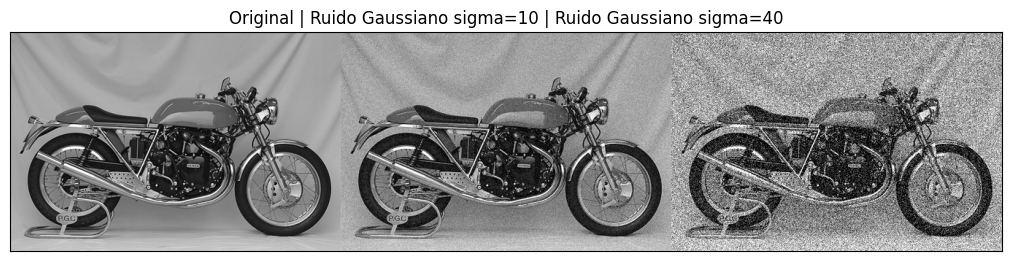

In [8]:
# ----------------------------------------------------------
# Visualización usando las funciones proporcionadas
# ----------------------------------------------------------

displayMI_ES(
    [im, gauss_10, gauss_40],
    title='Original | Ruido Gaussiano sigma=10 | Ruido Gaussiano sigma=40',
    factor=2
)

### Análisis: cómo afecta cada tipo de ruido

**Ruido Gaussiano.** Afecta a *todos* los píxeles, cada uno con una pequeña perturbación independiente. Con $\sigma=10$ la imagen se ve con un grano fino, más visible en las zonas lisas (la cortina del fondo, el depósito) que en las zonas con mucha textura, como el motor, donde el ruido se confunde con el detalle propio de la imagen. Con $\sigma=40$ el grano es tan fuerte que el fondo se vuelve una "nieve" y los detalles finos (radios, cables) apenas se distinguen. El recorte a $[0,255]$ tiene además un efecto curioso: en las zonas muy oscuras (neumáticos) el ruido negativo no puede bajar de 0, así que esas zonas se aclaran ligeramente de media. En las muy claras pasa lo contrario. Por eso, cerca de los extremos, el ruido deja de tener media cero.

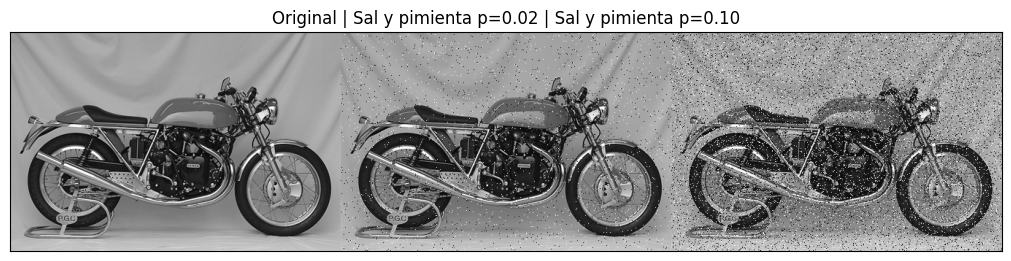

In [9]:
# Visualización del ruido sal y pimienta usando la función proporcionada
displayMI_ES(
    [im, sp_002, sp_010],
    title='Original | Sal y pimienta p=0.02 | Sal y pimienta p=0.10',
    factor=2
)

**Ruido sal y pimienta.** Es lo contrario: la mayoría de los píxeles no se toca, pero los afectados pierden por completo su valor y pasan a 0 o a 255. Se ve como puntos blancos y negros aislados, muy llamativos sobre el fondo gris medio. En cambio, la pimienta casi no se ve sobre los neumáticos negros y la sal se ve poco en los brillos del cromado, porque ahí el impulso se parece al valor original. Con $p=0{,}10$ la densidad de puntos ya es tan alta que tapa buena parte del detalle del motor.

#### Experimento extra: comprobación numérica del ruido

Antes de analizar las imágenes compruebo con números que las dos funciones generan el ruido pedido. No lo pide el enunciado, pero aporta una garantía: si las funciones no generasen el ruido pedido, todo el análisis posterior partiría de imágenes equivocadas. Además, explica detalles que a la vista no se aprecian, como por qué con $\sigma=40$ la desviación real se queda en unos 38. Uso estas medidas:

- **Ruido real.** Es la diferencia píxel a píxel entre la imagen con ruido y la original, $\text{ruidosa} - \text{original}$. En el ruido Gaussiano, su **media** debería ser cercana a 0 y su **desviación típica** cercana a la $\sigma$ pedida, porque el ruido se define como muestras de una normal $N(0,\sigma^2)$ que se suman a cada píxel (tema 2.1, tipos de ruido).
- **Píxeles en 0 o 255 (saturados).** Al sumar el ruido, algunos valores se salen del rango $[0,255]$ y `np.clip` los recorta al extremo. Por ejemplo, $240 + 50 = 290$ se queda en 255, así que el ruido que se añade de verdad es $+15$ y no $+50$. Cuantos más píxeles se recortan, menor es la desviación típica real respecto a la $\sigma$ pedida. Por eso cuento qué porcentaje de píxeles ha acabado en 0 o en 255.
- **Píxeles que cambian.** En sal y pimienta, el porcentaje de píxeles distintos de la original debería ser aproximadamente $p$, repartido a partes iguales entre pimienta (0) y sal (255).
- **MSE y PSNR.** Para resumir en un solo número cuánto se ha degradado la imagen uso el *peak signal-to-noise ratio* (PSNR). Es la medida habitual para evaluar el ruido y su eliminación cuando se conoce la imagen limpia, como aquí, donde el ruido es sintético (Szeliski, 2022, sección 2.3.3, ec. 2.118-2.120, y sección 3.4.2). Se calcula a partir del error cuadrático medio entre la original $I$ y la imagen modificada $\hat I$, con $n$ el número de píxeles:
  $$\text{MSE} = \frac{1}{n}\sum_x \big(I(x)-\hat I(x)\big)^2, \qquad \text{PSNR} = 10\log_{10}\frac{255^2}{\text{MSE}}\ \text{dB},$$
  donde 255 es el valor máximo de un píxel de 8 bits. Cuanto mayor es el PSNR, más se parece la imagen a la original; si fueran idénticas, el MSE sería 0 y el PSNR infinito. El PSNR no está en la teoría de los temas 1 y 2: lo he sacado de la bibliografía de la asignatura y lo uso como complemento a la inspección visual.

Las restas se hacen en `float64`, porque en `uint8` los resultados negativos no se guardan como tales sino que dan la vuelta.

In [10]:
# Comprobación numérica del ruido generado (no la pide el enunciado: la uso para
# verificar las dos funciones y para apoyar el análisis con datos)

def psnr(ref, test):  # PSNR de 'test' frente a la referencia 'ref'
    """PSNR (dB) de 'test' respecto a la imagen de referencia 'ref', ambas en [0, 255]."""
    mse = np.mean((ref.astype(np.float64) - test.astype(np.float64)) ** 2)  # error cuadrático medio (en float para no desbordar)
    return 10 * np.log10(255.0 ** 2 / mse)  # PSNR en dB: 10*log10(255^2 / MSE)

print(f'Tamaño de la imagen: {im.shape} ({im.size} píxeles)\n')  # dimensiones y número total de píxeles

for name, noisy in [('Gaussiano sigma=10', gauss_10), ('Gaussiano sigma=40', gauss_40)]:  # las dos imágenes con ruido Gaussiano
    diff = noisy.astype(np.float64) - im  # ruido añadido realmente en cada píxel
    saturated = 100 * np.mean((noisy == 0) | (noisy == 255))  # % de píxeles que han quedado en 0 o en 255
    print(f'{name:22s} | media del ruido real: {diff.mean():5.2f} | desv. típica real: {diff.std():5.2f} | '  # media y desviación típica del ruido real
          f'píxeles en 0 o 255: {saturated:5.2f}% | PSNR: {psnr(im, noisy):5.2f} dB')  # % saturado y PSNR frente a la original

for name, noisy in [('Sal y pimienta p=0.02', sp_002), ('Sal y pimienta p=0.10', sp_010)]:  # las dos imágenes con sal y pimienta
    changed = noisy != im  # True en los píxeles que han cambiado
    print(f'{name:22s} | píxeles que cambian: {100 * changed.mean():5.2f}% '  # % total de píxeles alterados
          f'(pimienta {100 * np.mean(changed & (noisy == 0)):4.2f}%, sal {100 * np.mean(changed & (noisy == 255)):4.2f}%) | '  # reparto entre pimienta (0) y sal (255)
          f'PSNR: {psnr(im, noisy):5.2f} dB')  # PSNR frente a la original

Tamaño de la imagen: (300, 453) (135900 píxeles)

Gaussiano sigma=10     | media del ruido real: -0.49 | desv. típica real:  9.99 | píxeles en 0 o 255:  0.64% | PSNR: 28.13 dB
Gaussiano sigma=40     | media del ruido real:  0.29 | desv. típica real: 38.34 | píxeles en 0 o 255:  5.76% | PSNR: 16.46 dB
Sal y pimienta p=0.02  | píxeles que cambian:  2.05% (pimienta 1.04%, sal 1.02%) | PSNR: 22.16 dB
Sal y pimienta p=0.10  | píxeles que cambian:  9.99% (pimienta 4.95%, sal 5.04%) | PSNR: 15.27 dB


#### Lo que muestran los números (experimento extra)

Los números de la celda anterior confirman que las dos funciones hacen lo que deben. Con $\sigma=10$ la desviación típica real del ruido es prácticamente 10. Su media sale -0,49 y no 0 porque `astype(np.uint8)` trunca los decimales en lugar de redondear (120,9 pasa a 120), así que cada píxel pierde de media medio nivel de gris; con $\sigma=40$ el recorte de las zonas oscuras compensa ese efecto y la media sale +0,29. Con $\sigma=40$ la desviación típica baja a unos 38: cerca del 6% de los píxeles se salen de $[0,255]$ y `np.clip` los recorta, lo que reduce la varianza. En sal y pimienta cambia el 2% y el 10% de los píxeles, repartidos casi a partes iguales entre sal y pimienta.

El PSNR cuantifica lo que se ve: 28,1 dB con $\sigma=10$ frente a 16,5 dB con $\sigma=40$, y 22,2 dB con $p=0{,}02$ frente a 15,3 dB con $p=0{,}10$. Aunque en sal y pimienta cambian muchos menos píxeles que con el Gaussiano, cada cambio es enorme (de un gris medio a 0 o 255) y pesa mucho en el error cuadrático. Esta diferencia de naturaleza, un error pequeño en todos los píxeles frente a uno muy grande en unos pocos, es la que explica qué filtro conviene en cada caso en el apartado siguiente.

<font color='blue'>2. **Filtrado.** Empleando exclusivamente funciones proporcionadas por OpenCV, aplica a las imágenes ruidosas:

   * <font color='blue'>un filtro de promedio, también llamado `box filter` (`cv2.blur`);
   * un filtro Gaussiano (`cv2.GaussianBlur`);
   * un filtro de mediana (`cv2.medianBlur`).

   <font color='blue'>Experimenta con al menos dos tamaños diferentes de kernel ($5$ y $11$). En el caso del filtro Gaussiano, utiliza los mismos tamaños de kernel y deja que OpenCV calcule automáticamente un valor de $\sigma$ adecuado para cada uno. Compara visualmente los resultados y analiza:

   * <font color='blue'>qué filtros resultan más apropiados para cada tipo de ruido;
   * cómo influye el tamaño del kernel;
   * cuál es el compromiso entre eliminación de ruido y conservación de detalles de la imagen.



### 2.A.2 Filtros empleados y parámetros

- `cv2.blur(im, (k, k))`: filtro de promedio. Convoluciona con una máscara $k \times k$ en la que todos los coeficientes valen $1/k^2$.
- `cv2.GaussianBlur(im, (k, k), 0)`: filtro Gaussiano. Al pasar `sigmaX = 0`, OpenCV calcula $\sigma$ a partir del tamaño con la fórmula de `getGaussianKernel`, $\sigma = 0{,}3\,((k-1)\cdot 0{,}5 - 1) + 0{,}8$. Como no indico `sigmaY`, toma el mismo valor.
- `cv2.medianBlur(im, k)`: filtro de mediana. No es una convolución: ordena los $k^2$ valores de la ventana y devuelve el central. Recibe un entero impar, no una tupla, porque la ventana siempre es cuadrada.

Además de los tamaños 5 y 11 que pide el enunciado, añado como experimento extra $33 \times 33$ para ver qué pasa cuando el kernel es claramente demasiado grande para los detalles de la imagen, que mide $300 \times 453$ píxeles.

Hay un detalle que conviene tener en cuenta antes de comparar: a igual tamaño de kernel, el filtro de promedio suaviza bastante más que el Gaussiano. Una máscara uniforme de lado $k$ tiene una desviación típica equivalente de $\sqrt{(k^2-1)/12}$, mientras que la Gaussiana automática de OpenCV es más estrecha:

| $k$ | $\sigma$ automática del Gaussiano | $\sigma$ equivalente del promedio |
|---|---|---|
| 5 | 1,1 | 1,41 |
| 11 | 2,0 | 3,16 |
| 33 | 5,3 | 9,52 |

Así que comparar los dos filtros con el mismo $k$ no es compararlos con el mismo grado de suavizado. Lo tengo en cuenta en el análisis.

Ninguna de estas funciones rellena el borde de la imagen con ceros: para calcular los píxeles del borde, OpenCV usa los valores de la propia imagen, reflejados (`blur` y `GaussianBlur`) o repetidos (`medianBlur`). Por eso no aparecen marcos oscuros alrededor de las imágenes filtradas.

In [11]:
def apply_filters(im, ksize):
    """
    Aplica los tres filtros solicitados en el enunciado.
    """

    mean = cv2.blur(
        # Imagen y tupla (ancho, alto) con el tamaño de la máscara uniforme
        im, (ksize, ksize)  # imagen de entrada y tamaño ksize x ksize
    )

    gaussian = cv2.GaussianBlur(
        # Mismo tamaño de máscara; sigmaX = 0 hace que OpenCV calcule sigma a partir de ksize
        im, (ksize, ksize), 0  # imagen, tamaño de la máscara y sigma automática
    )

    median = cv2.medianBlur(
        # Imagen y un entero impar con el lado de la ventana cuadrada
        im, ksize  # imagen y lado de la ventana
    )

    return mean, gaussian, median


def show_filter_results(noisy, description, ksize):
    """
    Muestra conjuntamente los resultados de los tres filtros.
    """

    mean, gaussian, median = apply_filters(noisy, ksize)

    displayMI_ES(
        [mean, gaussian, median],
        title=(description +
               f' - kernel {ksize}x{ksize} | '
               'Promedio | Gaussiano | Mediana'),
        factor=1.5
    )


# Dos tamaños diferentes de kernel
kernel_sizes = [5, 11]
# Experimento extra: un tercer tamaño, 33, como caso extremo
kernel_sizes = kernel_sizes + [33]  # tamaños de máscara a probar: 5, 11 y 33

noisy_images = [
    (gauss_10, 'Ruido Gaussiano sigma=10'),
    (gauss_40, 'Ruido Gaussiano sigma=40'),
    (sp_002, 'Sal y pimienta p=0.02'),
    (sp_010, 'Sal y pimienta p=0.10')
]

#### Experimento extra: medida objetiva con PSNR

La comparación visual es la que pide el enunciado, pero a veces engaña: dos imágenes pueden parecer igual de "limpias" con errores muy distintos. Por eso calculo el PSNR de cada resultado respecto a la imagen original sin ruido. Lo uso solo como complemento: el análisis de cada bloque se basa en la comparación visual, y las cifras de PSNR van aparte, en un párrafo marcado como **Extra**. Añado una fila de referencia en la que el filtro se aplica a la *imagen original*. Esa fila mide solo el detalle que destruye el filtro, sin ruido de por medio, y permite separar las dos cosas que entran en el compromiso: cuánto ruido se quita y cuánto detalle se pierde.

También cuento cuántos impulsos sobreviven a la mediana de $3 \times 3$ y de $5 \times 5$, es decir, cuántos píxeles quedan a 0 o 255 sin serlo en la original.

In [12]:
# PSNR (dB) de cada filtro respecto a la original sin ruido.
# La primera fila aplica los filtros a la propia original: solo mide la pérdida de detalle.
rows = [(im, 'Original (sin ruido)')] + noisy_images  # filas de la tabla: original y las cuatro con ruido

header = f"{'Imagen de entrada':26s}{'ruidosa':>9s}"  # primeras columnas de la cabecera
for k in kernel_sizes:  # un grupo de columnas por tamaño de máscara
    header += f"  |  {k}x{k}: prom / gaus / med"  # columnas de ese tamaño
print(header)  # imprime la cabecera
print('-' * len(header))  # línea separadora del mismo ancho

for noisy, desc in rows:  # una fila por imagen de entrada
    line = f'{desc:26s}' + (f'{"-":>9s}' if noisy is im else f'{psnr(im, noisy):9.1f}')  # nombre y PSNR sin filtrar ('-' en la original)
    for k in kernel_sizes:  # para cada tamaño de máscara
        mean, gaussian, median = apply_filters(noisy, k)  # aplica los tres filtros
        line += f'  |  {psnr(im, mean):10.1f} / {psnr(im, gaussian):4.1f} / {psnr(im, median):4.1f}'  # PSNR de cada filtro frente a la original
    print(line)  # imprime la fila

# Impulsos que sobreviven a la mediana: píxeles a 0 o 255 que no lo eran en la original
print('\nImpulsos que sobreviven al filtro de mediana:')  # título del recuento
for noisy, desc in [(sp_002, 'Sal y pimienta p=0.02'), (sp_010, 'Sal y pimienta p=0.10')]:  # las dos imágenes con sal y pimienta
    for k in [3, 5]:  # dos tamaños de mediana
        filtered = cv2.medianBlur(noisy, k)  # aplica la mediana k x k
        survivors = np.sum(((filtered == 0) | (filtered == 255)) & (im > 0) & (im < 255))  # píxeles en 0 o 255 que no lo eran en la original
        print(f'  {desc}, mediana {k}x{k}: {survivors} píxeles de {im.size}')  # imprime el recuento

Imagen de entrada           ruidosa  |  5x5: prom / gaus / med  |  11x11: prom / gaus / med  |  33x33: prom / gaus / med
------------------------------------------------------------------------------------------------------------------------
Original (sin ruido)              -  |        21.6 / 24.1 / 22.2  |        19.4 / 21.3 / 19.8  |        17.1 / 18.8 / 17.2
Ruido Gaussiano sigma=10       28.1  |        21.6 / 24.0 / 22.1  |        19.4 / 21.3 / 19.8  |        17.1 / 18.8 / 17.3
Ruido Gaussiano sigma=40       16.5  |        20.9 / 22.3 / 21.0  |        19.3 / 20.9 / 19.5  |        17.0 / 18.7 / 17.3
Sal y pimienta p=0.02          22.2  |        21.4 / 23.5 / 22.2  |        19.4 / 21.2 / 19.8  |        17.1 / 18.7 / 17.2
Sal y pimienta p=0.10          15.3  |        20.6 / 21.6 / 22.0  |        19.1 / 20.6 / 19.8  |        16.9 / 18.5 / 17.2

Impulsos que sobreviven al filtro de mediana:
  Sal y pimienta p=0.02, mediana 3x3: 11 píxeles de 135900
  Sal y pimienta p=0.02, mediana 5x5:

### Análisis y discusión de resultados

Muestro cada figura (una por imagen con ruido y tamaño de kernel) seguida de su análisis, y al final comento el efecto del tamaño del kernel y el compromiso entre ruido y detalle. El análisis de cada bloque se basa en la comparación visual que pide el enunciado. Las cifras de la tabla de PSNR (experimento extra) van aparte, redondeadas, en un párrafo marcado como **Extra**.

#### 1. Filtro más apropiado para cada tipo de ruido

##### Ruido Gaussiano $\sigma=10$

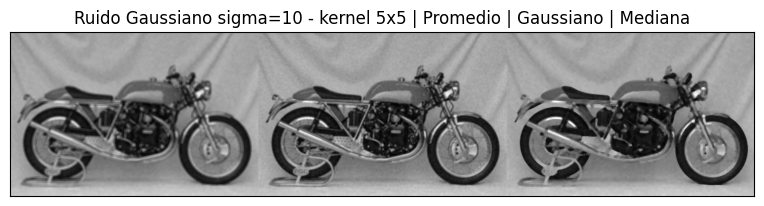

In [13]:
# Ruido Gaussiano sigma=10 con kernel 5x5
noisy, desc = noisy_images[0]  # imagen con ruido y su descripción
show_filter_results(noisy, desc, 5)  # muestra los tres filtros con ese tamaño

Con $5 \times 5$ los tres filtros reducen el ruido, pero en todos se sigue apreciando algo de grano.

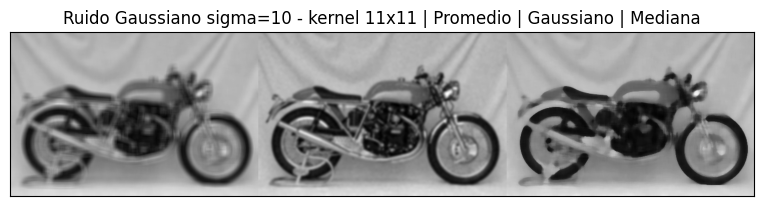

In [14]:
# Ruido Gaussiano sigma=10 con kernel 11x11
noisy, desc = noisy_images[0]  # imagen con ruido y su descripción
show_filter_results(noisy, desc, 11)  # muestra los tres filtros con ese tamaño

Con $11 \times 11$ el promedio y la mediana ya difuminan la imagen; la mediana, además, deja las zonas lisas más uniformes y hace que los bordes resalten, un efecto que se repite en sal y pimienta y que explico allí. El Gaussiano apenas difumina.

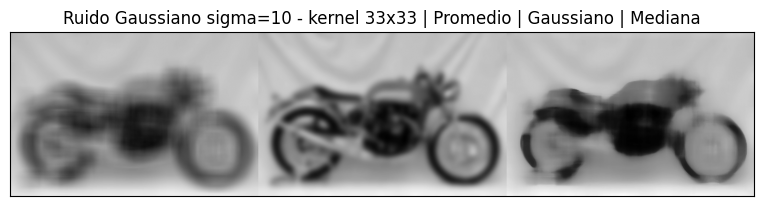

In [15]:
# Ruido Gaussiano sigma=10 con kernel 33x33 (experimento extra)
noisy, desc = noisy_images[0]  # imagen con ruido y su descripción
show_filter_results(noisy, desc, 33)  # muestra los tres filtros con ese tamaño

Con el tamaño extra de $33 \times 33$ las tres imágenes quedan borrosas, y el Gaussiano es el que menos.

**Extra (PSNR).** Aquí el PSNR muestra un resultado que no esperaba y que a la vista no se aprecia. Con $\sigma=10$, *todos* los filtros empeoran el PSNR: la imagen ruidosa tiene unos 28 dB y la mejor filtrada (Gaussiano $5 \times 5$) unos 24 dB. Además, esa cifra es casi idéntica a la del mismo filtro aplicado a la original sin ruido. Es decir, después de filtrar, el error que queda es prácticamente todo detalle perdido, no ruido. La imagen tiene mucha textura fina (motor, radios, cables) y con un ruido tan suave se pierde más de lo que se gana.

##### Ruido Gaussiano $\sigma=40$

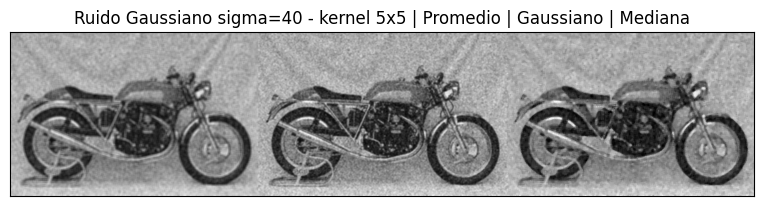

In [16]:
# Ruido Gaussiano sigma=40 con kernel 5x5
noisy, desc = noisy_images[1]  # imagen con ruido y su descripción
show_filter_results(noisy, desc, 5)  # muestra los tres filtros con ese tamaño

Con $5 \times 5$ ninguno de los tres filtros elimina el ruido: el grano se sigue viendo claramente en toda la imagen, aunque la moto no se ve emborronada.

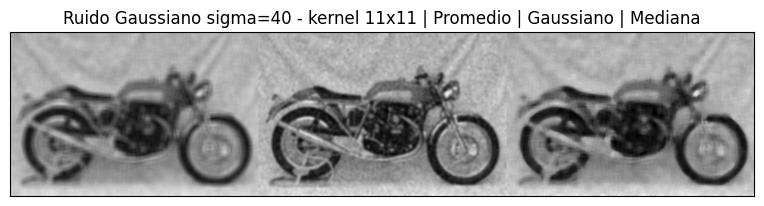

In [17]:
# Ruido Gaussiano sigma=40 con kernel 11x11
noisy, desc = noisy_images[1]  # imagen con ruido y su descripción
show_filter_results(noisy, desc, 11)  # muestra los tres filtros con ese tamaño

Con $11 \times 11$ el promedio y la mediana ya emborronan la imagen, y precisamente por eso podemos pensar que el grano se nota menos. El Gaussiano, en cambio, apenas emborrona, pero el grano sigue viéndose, con una mejora muy ligera respecto a $5 \times 5$.

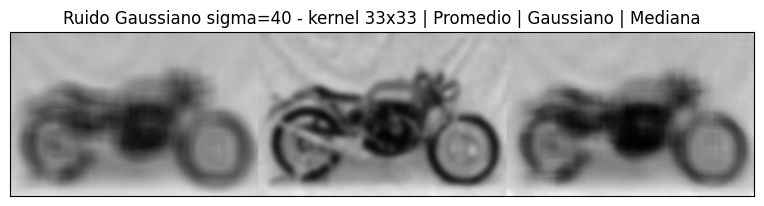

In [18]:
# Ruido Gaussiano sigma=40 con kernel 33x33 (experimento extra)
noisy, desc = noisy_images[1]  # imagen con ruido y su descripción
show_filter_results(noisy, desc, 33)  # muestra los tres filtros con ese tamaño

Con el tamaño extra de $33 \times 33$ las tres imágenes quedan emborronadas, el promedio y la mediana bastante: se identifica que es una moto, pero sus detalles ya no se ven, y el grano tampoco se aprecia porque se ha diluido con todo lo demás. El Gaussiano también emborrona, pero menos.

Que un filtro que promedia sirva para este ruido tiene una explicación sencilla: el ruido suma o resta al azar en cada píxel, así que al promediar varios vecinos esas subidas y bajadas se compensan entre sí (con $n$ vecinos, la varianza del ruido se divide aproximadamente por $n$). El problema es que, con un ruido tan fuerte, para que el grano deje de verse hay que promediar tantos vecinos que la imagen se emborrona. El Gaussiano emborrona menos porque pondera más los píxeles cercanos al centro, que son los que más se parecen al píxel que se quiere estimar, y porque, a igual tamaño de kernel, suaviza menos que el promedio: su $\sigma$ es 1,1, 2,0 y 5,3 para $k=5$, 11 y 33, mientras que el promedio equivale a 1,41, 3,16 y 9,52. Por eso conserva más detalle, pero también deja más grano. La mediana no está pensada para este ruido: no hay valores atípicos que descartar, sino que todos los píxeles están un poco desviados, así que con ventanas grandes se comporta como el promedio y emborrona en lugar de limpiar.

**Extra (PSNR).** Con $\sigma=40$, a diferencia de $\sigma=10$, sí compensa filtrar: la imagen ruidosa tiene 16,5 dB y el Gaussiano $5 \times 5$ llega a 22,3 dB. El Gaussiano obtiene el PSNR más alto de los tres filtros con todos los tamaños (22,3 / 20,9 / 18,7 dB con $k=5$, 11 y 33, frente a 20,9 / 19,3 / 17,0 del promedio y 21,0 / 19,5 / 17,3 de la mediana).

##### Sal y pimienta $p=0{,}02$

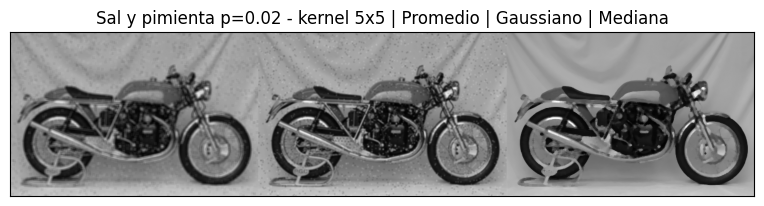

In [19]:
# Sal y pimienta p=0.02 con kernel 5x5
noisy, desc = noisy_images[2]  # imagen con ruido y su descripción
show_filter_results(noisy, desc, 5)  # muestra los tres filtros con ese tamaño

Con $5 \times 5$, el promedio y el Gaussiano no eliminan los impulsos: los puntos se siguen viendo por toda la imagen, solo algo atenuados, porque un filtro que promedia no puede quitar un valor extremo, solo repartirlo entre sus vecinos. La mediana, en cambio, los elimina por completo, pero la imagen cambia de aspecto: las zonas lisas quedan más uniformes y los bordes parecen destacar más que en la original. Es lo esperado: la mediana conserva los bordes nítidos, porque no promedia a través de ellos, y a la vez elimina la textura fina, porque esos detalles pequeños son minoría en la ventana igual que los impulsos. Al quedar las zonas más lisas y los contornos intactos, por contraste los bordes resaltan.

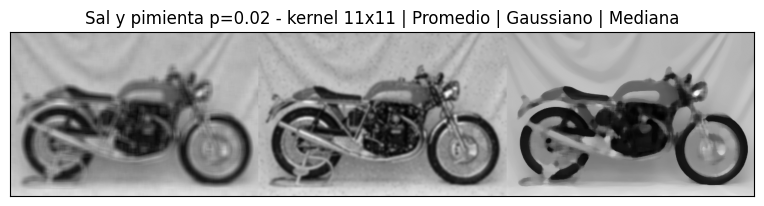

In [20]:
# Sal y pimienta p=0.02 con kernel 11x11
noisy, desc = noisy_images[2]  # imagen con ruido y su descripción
show_filter_results(noisy, desc, 11)  # muestra los tres filtros con ese tamaño

Con $11 \times 11$, el promedio y la mediana ya difuminan la imagen; el Gaussiano lo hace menos, aunque todavía se distinguen algunos puntos atenuados.

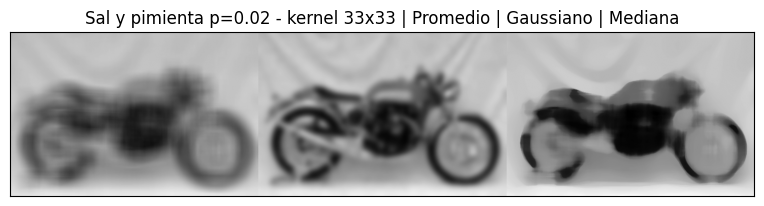

In [21]:
# Sal y pimienta p=0.02 con kernel 33x33 (experimento extra)
noisy, desc = noisy_images[2]  # imagen con ruido y su descripción
show_filter_results(noisy, desc, 33)  # muestra los tres filtros con ese tamaño

Con el tamaño extra de $33 \times 33$ los tres difuminan la imagen, incluido el Gaussiano, aunque este sigue siendo el que más detalle conserva.

**Extra (PSNR).** El PSNR también tiene sus límites. La imagen con ruido tiene 22,2 dB, y la mediana $5 \times 5$ obtiene exactamente lo mismo, 22,2 dB, aunque a la vista la mejora es evidente. El Gaussiano obtiene más PSNR que la mediana con los tres tamaños (23,5 / 21,2 / 18,7 dB con $k=5$, 11 y 33, frente a 22,2 / 19,8 / 17,2 de la mediana y 21,4 / 19,4 / 17,1 del promedio), aunque deja los puntos a la vista. La razón es que el PSNR solo mide el error cuadrático medio: unos pocos puntos atenuados pesan menos que la pérdida de textura fina que introduce la mediana en toda la imagen. Por eso conviene mirar las dos cosas, y para sal y pimienta me quedo con la mediana, porque el defecto que deja el Gaussiano es mucho más visible. Szeliski (2022, sección 3.4.2) advierte de esta limitación: el PSNR tiende a favorecer los resultados suaves o promediados, y una forma mejor de medir la calidad es usar medidas basadas en la percepción, como el SSIM (structural similarity; Wang, Bovik et al., 2004), que compara brillo, contraste y estructura en ventanas locales en lugar de píxeles sueltos.

##### Sal y pimienta $p=0{,}10$

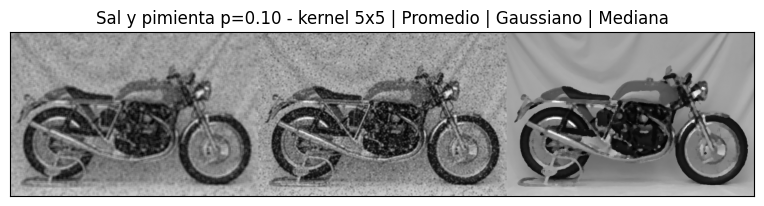

In [22]:
# Sal y pimienta p=0.10 con kernel 5x5
noisy, desc = noisy_images[3]  # imagen con ruido y su descripción
show_filter_results(noisy, desc, 5)  # muestra los tres filtros con ese tamaño

El patrón es el mismo que con $p=0{,}02$, pero con muchos más puntos. Con $5 \times 5$, el promedio y el Gaussiano dejan la imagen claramente sucia: cada impulso se reparte entre sus vecinos y, con un 10% de píxeles afectados, los puntos atenuados cubren toda la imagen. La mediana vuelve a eliminarlos por completo y deja la imagen limpia, con el mismo efecto de antes: zonas lisas más uniformes y bordes que resaltan. Funciona porque ordena los valores de la ventana, deja los 0 y los 255 en los extremos y devuelve un valor que casi siempre pertenece a un píxel sano.

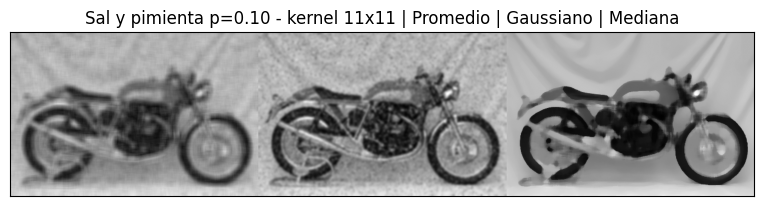

In [23]:
# Sal y pimienta p=0.10 con kernel 11x11
noisy, desc = noisy_images[3]  # imagen con ruido y su descripción
show_filter_results(noisy, desc, 11)  # muestra los tres filtros con ese tamaño

Con $11 \times 11$, el promedio y la mediana difuminan la imagen, y en el Gaussiano, que difumina menos, los puntos siguen viéndose.

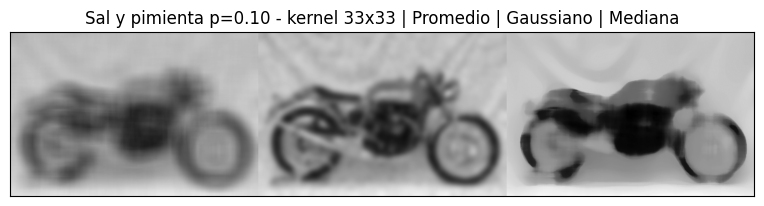

In [24]:
# Sal y pimienta p=0.10 con kernel 33x33 (experimento extra)
noisy, desc = noisy_images[3]  # imagen con ruido y su descripción
show_filter_results(noisy, desc, 33)  # muestra los tres filtros con ese tamaño

Con el tamaño extra de $33 \times 33$ los tres difuminan la imagen; el Gaussiano es el que más detalle conserva.

Con este nivel de ruido la mediana es claramente el filtro adecuado: es el único que elimina los impulsos sin necesidad de emborronar la imagen.

**Extra (recuento de impulsos y PSNR).** Según el recuento, con la mediana $3 \times 3$ sobreviven 36 impulsos y con $5 \times 5$ solo 1, de 135.900 píxeles. Aquí, a diferencia de $p=0{,}02$, el PSNR sí da la razón a la mediana con $5 \times 5$: la imagen con ruido tiene 15,3 dB y la mediana llega a 22,0 dB, frente a 21,6 dB del Gaussiano y 20,6 dB del promedio. Además, ese 22,0 dB coincide prácticamente con el de la mediana aplicada a la original sin ruido (22,2 dB): el ruido desaparece casi por completo y lo que queda es la pérdida de detalle propia del filtro. Con ventanas mayores el Gaussiano vuelve a ganar en PSNR (20,6 y 18,5 dB frente a 19,8 y 17,2 de la mediana), por la misma razón que con $p=0{,}02$.

#### 2. Influencia del tamaño del kernel

A la vista, al aumentar el tamaño el ruido se reduce más, pero la imagen pierde cada vez más detalle: cuanto más grande es la ventana, más detalle se destruye, haya ruido o no.

- $5 \times 5$. Es el mejor compromiso para esta imagen: el ruido se reduce y la moto no se emborrona. Con sal y pimienta, la mediana ya elimina los puntos; con ruido Gaussiano, en cambio, el grano se sigue viendo, claramente con $\sigma=40$.
- $11 \times 11$. El ruido Gaussiano se reduce mucho más: con el promedio y la mediana apenas queda grano, y el Gaussiano, que suaviza menos, conserva algo. A cambio, los detalles finos se difuminan y el promedio deja la imagen claramente borrosa. La mediana empieza a borrar las estructuras finas. Una línea de pocos píxeles de ancho nunca es mayoría dentro de una ventana de 121 píxeles, así que la mediana la sustituye por el valor del fondo.
- $33 \times 33$ (experimento extra). Los tres filtros destruyen gran parte del detalle. El promedio es el que más emborrona, porque equivale a una Gaussiana de $\sigma \approx 9{,}5$, frente a $\sigma \approx 5{,}3$ del Gaussiano. La mediana deja zonas planas separadas por bordes nítidos, porque conserva los bordes pero elimina cualquier estructura más estrecha que media ventana (unos 16 píxeles).

**Extra (PSNR).** La tabla lo confirma: en todas las filas el PSNR baja al aumentar el tamaño, también en la fila de referencia, donde no hay ruido y solo se mide el detalle destruido. El $5 \times 5$ tiene el mejor PSNR en todos los casos. Con $\sigma=40$, el Gaussiano $5 \times 5$ obtiene 22,3 dB, por debajo de los 24,1 dB que consigue sobre la original sin ruido, y esa diferencia es ruido que no ha eliminado. Con $11 \times 11$ obtiene 20,9 dB frente a 21,3 dB: según el PSNR, ya apenas queda ruido. Con $33 \times 33$, incluso sobre la original, el PSNR baja a 17-19 dB.

#### 3. Compromiso entre eliminación de ruido y conservación de detalles

El ruido y los detalles finos ocupan la misma parte del espectro: las altas frecuencias. Un filtro paso bajo como el promedio o el Gaussiano no puede distinguir si una variación rápida de intensidad es ruido o el borde de un radio, así que atenúa las dos cosas. Cuanto mayor es el kernel, más ruido se elimina, pero también más detalle, porque cada píxel se promedia con más vecinos: cualquier variación rápida, sea un grano de ruido o el borde de un radio, queda más diluida entre ellos. El caso de $\sigma=10$ lo muestra de forma muy clara: con poco ruido, filtrar hace más daño que bien (lo cuantifica el PSNR del experimento extra).

La mediana rompe en parte este compromiso para el ruido impulsivo. No promedia a través de los bordes, sino que elige un valor que ya existe, así que conserva los bordes nítidos mientras el objeto que se quiere preservar sea más ancho que media ventana. Cuando no lo es, como los radios con $11 \times 11$, la mediana lo borra por completo, de una forma mucho más brusca que el desenfoque gradual de un filtro lineal. Mi conclusión práctica es usar la ventana más pequeña que reduzca el ruido lo suficiente sin emborronar la imagen. Para esta imagen, eso es $5 \times 5$ en los cuatro casos, con Gaussiano para el ruido Gaussiano y mediana para el sal y pimienta, aunque con $\sigma=40$ ningún tamaño consigue quitar el grano sin emborronar.

<font color='blue'>3. **Ruido, suavizado y detección de bordes.** Utiliza el operador Sobel de OpenCV (`cv2.Sobel`), tanto con kernels de tamaño $3\times3$ y $11\times11$, para obtener la magnitud del gradiente (`cv2.magnitude`) de:

   * <font color='blue'>la imagen original;
   * una de las imágenes con ruido Gaussiano ($\sigma=40$);
   * esa misma imagen después de aplicar un filtrado Gaussiano ($5\times5$);
   * una imagen afectada por ruido sal y pimienta ($p=0.10$);
   * esa misma imagen después de aplicar un filtro de mediana ($5\times5$).

   <font color='blue'>Compara los resultados y explica qué efecto tiene el ruido sobre la detección de bordes, así como el impacto que tiene el tamaño del kernel de derivadas, y por qué puede ser conveniente realizar un suavizado antes de calcular derivadas.

### 2.A.3 Cálculo de la magnitud del gradiente

`cv2.Sobel(im, cv2.CV_64F, dx, dy, ksize=k)` calcula la derivada parcial en $x$ (`dx=1, dy=0`) o en $y$ (`dx=0, dy=1`). La máscara de Sobel es separable: combina una diferencia en la dirección de derivación con un suavizado binomial en la perpendicular. Para $3 \times 3$ y la derivada en $x$:

$$
\begin{pmatrix} -1 & 0 & 1 \\ -2 & 0 & 2 \\ -1 & 0 & 1 \end{pmatrix} = \begin{pmatrix} 1 \\ 2 \\ 1 \end{pmatrix} \begin{pmatrix} -1 & 0 & 1 \end{pmatrix}
$$

Con `ksize` mayor, OpenCV construye ambos factores con coeficientes binomiales más largos. Así, el suavizado transversal es más ancho y la diferencia se calcula también sobre una zona mayor.

Uso `cv2.CV_64F` como profundidad de salida porque una derivada puede ser negativa, por ejemplo al pasar de claro a oscuro. Con salida `uint8` esos valores se recortarían a 0 y se perdería la mitad de los bordes. La magnitud se obtiene con `cv2.magnitude(gx, gy)` $= \sqrt{g_x^2 + g_y^2}$, que no depende de la orientación del borde.

**Visualización.** No uso `displayMI_ES` para estas figuras porque normaliza todas las imágenes apiladas con un único mínimo y máximo global. Con cinco magnitudes de rangos muy distintos, las ruidosas, cuyos máximos son mucho mayores, dejan casi negras a las demás. Además, con cinco imágenes y cuatro columnas, la función rellena la segunda fila con negro. En su lugar dibujo cada magnitud en su propio subplot con *la misma escala de grises para los seis paneles de cada figura*: de 0 al percentil 99 de la magnitud de la imagen original. Así la comparación entre variantes es justa: si una imagen se ve más clara es porque tiene más gradiente. En la original, solo el 1% de los valores más altos satura a blanco; en las imágenes con ruido satura una proporción mayor, porque el ruido aumenta la magnitud del gradiente. Los paneles se organizan en dos filas, una por tipo de ruido, y cada fila se lee "original, con ruido, filtrada". En el título indico la media de la magnitud como dato orientativo.

In [25]:
def sobel_magnitude(im, ksize):
    """
    Calcula la magnitud del gradiente utilizando Sobel
    con un kernel de tamaño ksize x ksize.
    """

    gx = cv2.Sobel(
        # Derivada en x (dx=1, dy=0): responde a los bordes verticales.
        # Salida en float64 para no perder las derivadas negativas
        im, cv2.CV_64F, 1, 0, ksize=ksize  # imagen, tipo de salida, dx=1, dy=0 y tamaño
    )

    gy = cv2.Sobel(
        # Derivada en y (dx=0, dy=1): responde a los bordes horizontales
        im, cv2.CV_64F, 0, 1, ksize=ksize  # imagen, tipo de salida, dx=0, dy=1 y tamaño
    )

    magnitude = cv2.magnitude(gx, gy)  # sqrt(gx^2 + gy^2), píxel a píxel

    return magnitude

In [26]:
# Ruido Gaussiano -> suavizado Gaussiano
gauss_filtered = cv2.GaussianBlur(
    gauss_40,  # imagen con ruido Gaussiano sigma=40
    (5, 5),    # tamaño de la máscara
    0          # sigma = 0: OpenCV la calcula a partir del tamaño (sigma = 1.1 para 5x5)
)

# Ruido sal y pimienta -> filtro de mediana
sp_filtered = cv2.medianBlur(
    sp_010,    # imagen con ruido sal y pimienta p=0.10
    5          # lado de la ventana cuadrada (entero impar)
)

In [27]:
# Mismo cálculo que el bucle de la plantilla (for ksize in [3, 11]:), como función para llamarla una vez por tamaño
def show_sobel(ksize):  # dibuja las seis magnitudes con Sobel ksize x ksize

    # Magnitud del gradiente de las cinco variantes que pide el enunciado
    mag_orig = sobel_magnitude(im, ksize)  # original sin ruido
    mag_gauss_noisy = sobel_magnitude(gauss_40, ksize)  # con ruido Gaussiano sigma=40
    mag_gauss_filt = sobel_magnitude(gauss_filtered, ksize)  # ruido Gaussiano tras GaussianBlur 5x5
    mag_sp_noisy = sobel_magnitude(sp_010, ksize)  # con sal y pimienta p=0.10
    mag_sp_filt = sobel_magnitude(sp_filtered, ksize)  # sal y pimienta tras medianBlur 5x5

    # Dos filas (una por tipo de ruido): original | con ruido | filtrada.
    # La original se repite en la segunda fila para tenerla al lado como referencia.
    panels = [  # pares (magnitud, título) en el orden de la cuadrícula
        (mag_orig, 'Original'),  # fila 1, columna 1
        (mag_gauss_noisy, 'Ruido Gaussiano sigma=40'),  # fila 1, columna 2
        (mag_gauss_filt, 'Gaussiano sigma=40 + GaussianBlur 5x5'),  # fila 1, columna 3
        (mag_orig, 'Original'),  # fila 2, columna 1 (referencia repetida)
        (mag_sp_noisy, 'Sal y pimienta p=0.10'),  # fila 2, columna 2
        (mag_sp_filt, 'Sal y pimienta p=0.10 + medianBlur 5x5'),  # fila 2, columna 3
    ]

    # Misma escala de grises en todos los paneles: de 0 al percentil 99 de la original
    vmax = np.percentile(mag_orig, 99)  # valor que se pinta en blanco

    fig, axs = plt.subplots(2, 3, figsize=(16, 11))  # cuadrícula de 2x3 paneles
    for ax, (mag, name) in zip(axs.flat, panels):  # empareja cada panel con su imagen y su título
        ax.imshow(mag, cmap='gray', vmin=0, vmax=vmax)  # dibuja la magnitud con la escala común
        ax.set_title(f'{name}\nmedia de la magnitud = {mag.mean():.1f}', fontsize=11)  # título con la media de la magnitud
        ax.axis('off')  # oculta los ejes
    fig.suptitle(f'Magnitud del gradiente con Sobel {ksize}x{ksize} (escala común: 0 - {vmax:.0f})',  # título general
                 fontsize=14, fontweight='bold')  # tamaño de letra y negrita
    plt.tight_layout(h_pad=3)  # deja espacio vertical para que los títulos no se pisen
    plt.show()  # muestra la figura

> **Nota.** Con el fin de facilitar la corrección al profesorado, se analiza cada imagen por separado.

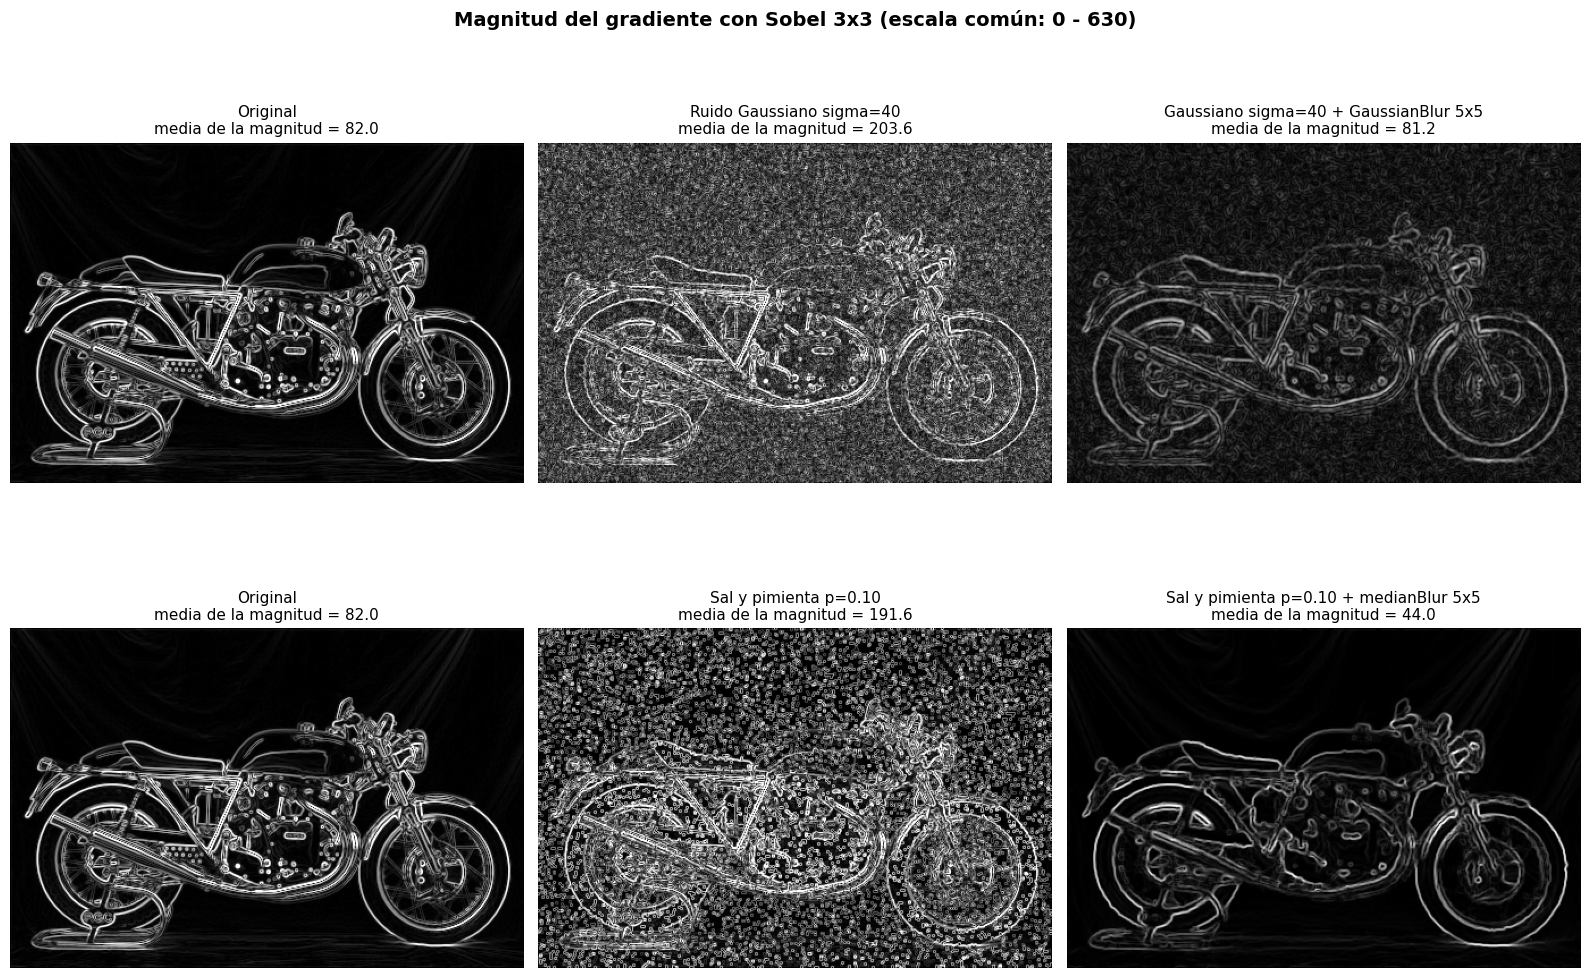

In [28]:
show_sobel(3)  # Sobel 3x3

### Análisis del impacto del ruido y el suavizado en la detección de bordes

#### 1. Efecto del ruido sobre la detección de bordes

Una derivada mide cuánto cambia la intensidad entre píxeles vecinos, y el ruido es justamente eso: cambios bruscos de un píxel a otro. Como hemos visto en el tema 2, las variaciones bruscas de intensidad corresponden a las altas frecuencias de la imagen, y la derivada actúa como un filtro paso alto: refuerza esas frecuencias, al contrario que el suavizado, que las atenúa. El ruido es el caso extremo de variación brusca, porque cambia de un píxel al siguiente, así que la derivada lo amplifica tanto o más que a los bordes reales.

- **Ruido Gaussiano $\sigma=40$ con Sobel $3 \times 3$.** Toda la imagen se llena de una textura brillante y la media de la magnitud se dispara respecto a la original. Las diferencias entre píxeles vecinos que provoca el ruido son de un tamaño parecido a las de muchos bordes reales, así que Sobel no puede distinguirlas y el fondo se llena de falsos bordes. Los contornos de mayor contraste (ruedas, chasis, depósito) se siguen distinguiendo, pero los detalles finos del motor quedan enterrados en el ruido.
- **Sal y pimienta $p=0{,}10$ con Sobel $3 \times 3$.** Cada impulso es un salto de hasta 255 niveles respecto a sus vecinos, así que genera un pequeño anillo de gradiente muy alto alrededor del píxel. Con un 10% de píxeles afectados, estos anillos cubren el fondo y compiten con los bordes reales.

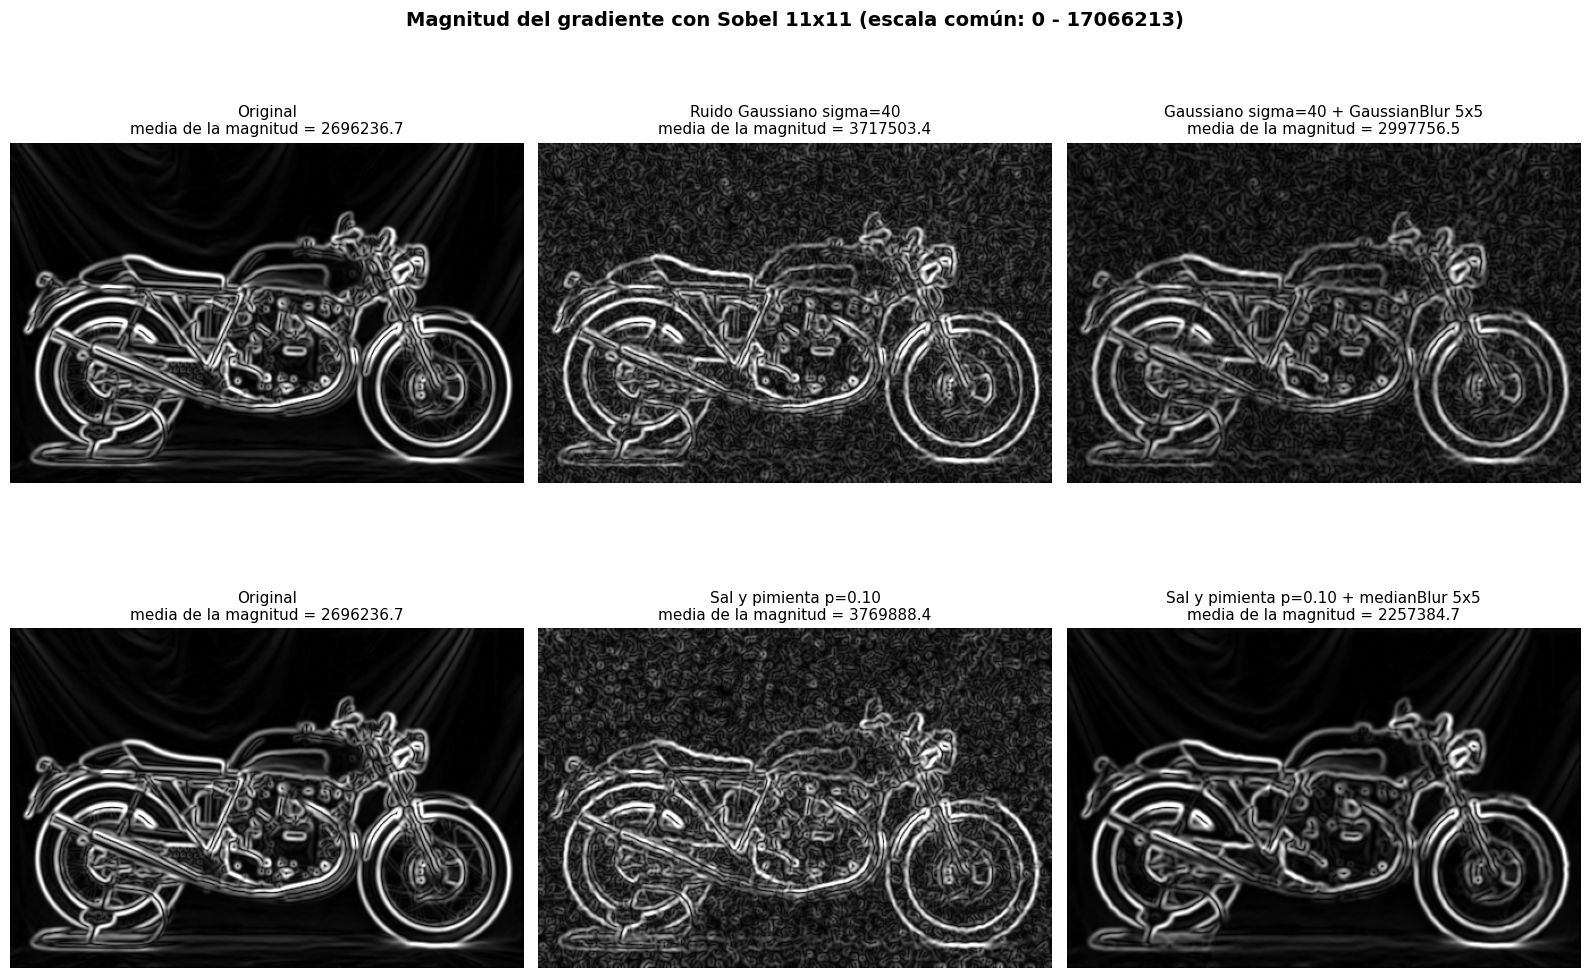

In [29]:
show_sobel(11)  # Sobel 11x11

#### 2. Impacto del tamaño del kernel de derivadas ($3 \times 3$ frente a $11 \times 11$)

- **$3 \times 3$.** Localiza muy bien: en la imagen original los bordes son finos y se ven detalles pequeños como los radios. Su suavizado transversal ($[1,2,1]$) es mínimo, así que apenas protege contra el ruido.
- **$11 \times 11$.** Derivar con un kernel grande equivale a suavizar más antes de derivar. Por eso, con $11 \times 11$ los contornos principales de la moto se distinguen en las imágenes con ruido, sin prefiltrar, con más claridad que con $3 \times 3$. El precio es la localización: los bordes salen gruesos, los detalles próximos se funden (los radios ya no se separan) y la imagen original pierde los bordes finos. Los valores de la magnitud son también mucho mayores que con $3 \times 3$, porque la máscara tiene más coeficientes y más grandes. Eso no es un problema para comparar, porque cada figura tiene su propia escala común.

#### 3. Por qué conviene suavizar antes de derivar

La derivada es muy sensible: una perturbación pequeña en la imagen, como el ruido, produce un cambio grande en el resultado. La solución es suavizar primero. Además, como la convolución es asociativa y conmutativa, da igual hacerlo en dos pasos (suavizar y después derivar) o en uno solo, convolucionando con la derivada de la Gaussiana (tema 2.2; Szeliski, 2022, apartado 7.2.1):

$$
\frac{\partial}{\partial x}(I * G_\sigma) = I * \frac{\partial G_\sigma}{\partial x}, \qquad \nabla(I * G_\sigma) = I * \nabla G_\sigma
$$

Derivar la imagen suavizada es lo mismo que convolucionar la original con la derivada de la Gaussiana. Esta es la idea que hay detrás de Sobel, cuyo factor binomial es una aproximación discreta de una Gaussiana, y de detectores como Canny.  En términos de frecuencia, la Gaussiana es un filtro paso bajo que atenúa las altas frecuencias, donde está el ruido, antes de que la derivada, que es un filtro paso alto, las refuerce.

Las figuras lo confirman en los dos casos:

- **Gaussiano $\sigma=40$ + GaussianBlur $5 \times 5$.** La textura de ruido baja mucho y los contornos de la moto vuelven a ser continuos, aunque con $3 \times 3$ queda todavía un fondo granulado. Un $5 \times 5$ con $\sigma \approx 1{,}1$ no basta para un ruido tan fuerte. Con $11 \times 11$, al sumarse los dos suavizados, el resultado mejora respecto a $3 \times 3$, aunque en el fondo sigue quedando textura del ruido.
- **Sal y pimienta + medianBlur $5 \times 5$.** Es el caso más claro de eliminación del ruido: desaparecen todos los anillos y el fondo queda incluso más limpio que en la original, porque la mediana también elimina la textura suave de la cortina. Los contornos principales se conservan nítidos y en su sitio, porque la mediana no desplaza los bordes. El precio es la pérdida de detalle fino: los radios y buena parte del motor desaparecen, y la media de la magnitud queda por debajo de la de la original (44 frente a 82 con $3 \times 3$). Al derivar ya no queda nada espurio, pero tampoco todo lo que había.

La comparación también enseña que el suavizado tiene que estar adaptado al ruido. Para sal y pimienta, el suavizado Gaussiano que lleva incorporado Sobel $11 \times 11$ mejora el resultado, pero no lo arregla: reparte los impulsos en manchas. La mediana previa, en cambio, los elimina antes de derivar.

## <font color='blue'>B) Discretización de kernels Gaussianos 1D (1.5 puntos)

<font color='blue'>En este apartado se deben realizar las siguientes tareas (evitando, en todo momento, el uso de funciones de OpenCV):

1. Calcular las máscaras discretas 1D de la Gaussiana, así como su primera y segunda derivadas (con la escala normalizada), considerando que la entrada a dicha función de creación de máscaras 1D puede ser tanto un posible sigma como un posible tamaño de máscara. Se proporcionará exactamente uno de los dos parámetros, $\sigma$ o $T$. El tamaño $T$ será siempre impar. Se debe exlicar detalladamente el proceso seguido a la hora de discretizar los kernels Gaussianos.
2. Emplear los siguientes valores de sigma ($\{0.25, 1.5, 4, 8, 16\}$) y los siguientes valores de tamaño de máscara ($\{3,5,7,15\}$), y mostrar el perfil (es decir, la silueta de las máscaras como funciones 1D) para verificar que las máscaras creadas son correctas.
3. Describir/explicar/analizar si las formas de dichos kernels tienen sentido y se corresponden con lo que esperaríamos ver.
4. ¿De qué manera se normalizan las derivadas de orden 0, 1 y 2; y qué ocurre, es decir, cuál es el efecto, si no se realizan estas normalizaciones?

<font color='blue'>La aplicación y uso de estos kernels 1D lo veremos en la práctica 2 de la asignatura.

### 2.B Proceso de discretización

**Funciones continuas.** Parto de la Gaussiana sin la constante $1/(\sigma\sqrt{2\pi})$, que solo escala y que más adelante sustituyo por una normalización discreta:

$$
g(x) = e^{-\frac{x^2}{2\sigma^2}}, \qquad
g'(x) = -\frac{x}{\sigma^2}\, e^{-\frac{x^2}{2\sigma^2}}, \qquad
g''(x) = \frac{x^2-\sigma^2}{\sigma^4}\, e^{-\frac{x^2}{2\sigma^2}}
$$

La primera derivada sale de la regla de la cadena. La segunda, de derivar el producto $-\frac{x}{\sigma^2} \cdot g(x)$: $-\frac{1}{\sigma^2}g(x) + \frac{x^2}{\sigma^4}g(x)$.

**Relación entre $\sigma$ y el tamaño $T$.** Casi toda el área de la Gaussiana (el 99,7%) está en $[-3\sigma, 3\sigma]$, así que la máscara cubre las posiciones enteras $x \in \{-k, \dots, 0, \dots, k\}$, con $T = 2k+1$ siempre impar para que exista un píxel central:

- Si me dan $\sigma$: tomo el menor entero $k \geq 3\sigma$, es decir, $k = \lceil 3\sigma \rceil$ y $T = 2\lceil 3\sigma \rceil + 1$. Por ejemplo, $\sigma = 1 \Rightarrow T = 7$.
- Si me dan $T$: despejo de $k = 3\sigma$, con $k = (T-1)/2$, y obtengo $\sigma = (T-1)/6$. Por ejemplo, $T = 5 \Rightarrow \sigma = 0{,}67$.

**Muestreo.** Evalúo la expresión analítica de cada función en esas posiciones enteras, sin aproximar las derivadas con diferencias finitas.

**Normalización.**

- Orden 0: divido por la suma de las muestras, $\sum_i g(x_i)$, para que la máscara sume exactamente 1.
- Órdenes 1 y 2: no se puede dividir por su propia suma, porque vale (casi) 0. Lo que hago es multiplicar por $\sigma$ y por $\sigma^2$ respectivamente (normalización de escala) y dividir por *la misma* constante que el orden 0, $\sum_i g(x_i)$.

Divido también las derivadas por $\sum_i g(x_i)$ para devolverles la constante que quité al principio. Esa constante sale del área bajo la campana:

$$
\int_{-\infty}^{\infty} e^{-\frac{x^2}{2\sigma^2}}\,dx = \sigma\sqrt{2\pi}
$$

Por eso la Gaussiana normalizada lleva delante $1/(\sigma\sqrt{2\pi})$: así su área vale 1. La suma de las muestras es la versión discreta de esa área. Cada muestra es la altura de la curva en un píxel y los píxeles están separados una unidad, así que sumarlas equivale a sumar rectángulos de anchura 1 bajo la curva. Por ejemplo, con $\sigma=4$ la suma de las 25 muestras da 10,01, prácticamente $4\sqrt{2\pi} \approx 10{,}03$.

Así, las tres máscaras salen *de la misma Gaussiana normalizada*, que es la que suponen las diapositivas al explicar la normalización de escala. Si no lo hiciera, al multiplicar $g'$ por $\sigma$ la máscara arrastraría un factor $\sigma\sqrt{2\pi}$ de más y la respuesta crecería con $\sigma$ en lugar de mantenerse constante. Lo compruebo con un experimento después de las gráficas.

In [30]:
"""
    Evalúa la función Gaussiana 1D de media cero para una posición x
    y una desviación estándar sigma.
"""
def GaussFunc(x,sigma):
    # Sin la constante 1/(sigma*sqrt(2*pi)): la forma no cambia y la máscara
    # se normaliza después dividiendo por la suma de sus muestras
    return np.exp(-x**2 / (2.0 * sigma**2))  # e^(-x^2 / (2*sigma^2))

"""
    Evalúa la primera derivada de la función Gaussiana 1D de media cero
    para una posición x y una desviación estándar sigma.
"""
def GaussDeriv1Func(x,sigma):
    # g'(x) = -(x / sigma^2) * g(x)
    return -(x / sigma**2) * GaussFunc(x, sigma)  # regla de la cadena

"""
    Evalúa la segunda derivada de la función Gaussiana 1D de media cero
    para una posición x y una desviación estándar sigma.
"""
def GaussDeriv2Func(x,sigma):
    # g''(x) = ((x^2 - sigma^2) / sigma^4) * g(x)
    return ((x**2 - sigma**2) / sigma**4) * GaussFunc(x, sigma)  # derivada del producto -(x/sigma^2)*g(x)

"""
    Construye un kernel Gaussiano 1D discreto, o una de sus derivadas,
    a partir de sigma o del tamaño deseado para la máscara.

    El parámetro order determina el tipo de kernel:
        order = 0 -> Gaussiana
        order = 1 -> primera derivada de la Gaussiana
        order = 2 -> segunda derivada de la Gaussiana

    Debe proporcionarse sigma o sizeMask, pero no ambos simultáneamente.
    Si solamente se proporciona sigma, debe determinarse un tamaño
    apropiado para el kernel. Si solamente se proporciona sizeMask,
    debe obtenerse un valor apropiado de sigma.

    El kernel debe construirse discretizando la función correspondiente
    en las posiciones espaciales que forman la máscara y debe aplicarse
    la normalización apropiada según el orden de la derivada.
"""
def gaussianMask1D(sigma=0, sizeMask=0, order=0):
    if sigma > 0 and sizeMask == 0:  # caso 1: nos dan sigma
        # Dado sigma: menor entero k que cumple k >= 3*sigma, y T = 2k + 1
        k = int(np.ceil(3.0 * sigma))  # k = techo de 3*sigma
        sizeMask = 2 * k + 1  # tamaño impar de la máscara
    elif sizeMask > 0 and sigma == 0:  # caso 2: nos dan el tamaño
        # Dado T (impar): k = (T - 1) / 2 = 3*sigma  ->  sigma = (T - 1) / 6
        if sizeMask % 2 == 0:  # el tamaño tiene que ser impar
            raise ValueError('El tamaño de la máscara debe ser impar.')  # error si es par
        k = (sizeMask - 1) // 2  # radio de la máscara
        sigma = k / 3.0  # sigma = (T - 1) / 6
    else:  # se han dado los dos parámetros o ninguno
        raise ValueError('Debe proporcionarse exactamente uno de los dos parámetros: sigma o sizeMask.')  # error de uso

    # Posiciones enteras centradas en 0: -k, ..., 0, ..., k
    x = np.arange(-k, k + 1)  # vector de posiciones de la máscara

    # Suma de las muestras de la Gaussiana: versión discreta de sigma*sqrt(2*pi).
    # Se usa como constante de normalización común para los tres órdenes
    norm = np.sum(GaussFunc(x, sigma))  # constante de normalización

    if order == 0:  # Gaussiana
        mask = GaussFunc(x, sigma) / norm                    # suma exactamente 1
    elif order == 1:  # primera derivada
        mask = sigma * GaussDeriv1Func(x, sigma) / norm      # escala normalizada (sigma^1)
    elif order == 2:  # segunda derivada
        mask = sigma**2 * GaussDeriv2Func(x, sigma) / norm   # escala normalizada (sigma^2)
    else:  # orden no válido
        raise ValueError('El parámetro order debe ser 0, 1 o 2.')  # error si order no es 0, 1 o 2

    return mask

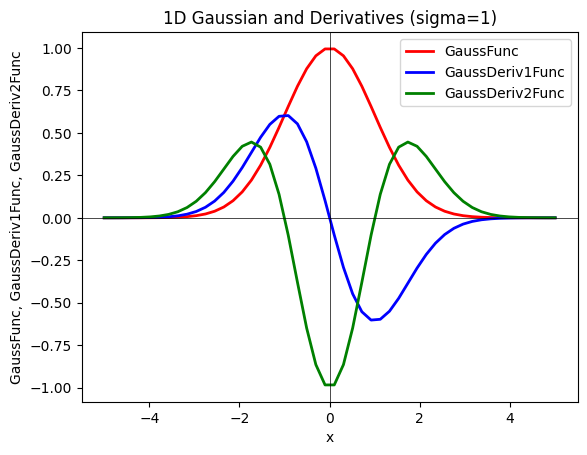

In [31]:
# Con la siguiente figura verificamos que las funciones Gaussianas implementadas son correctas
plt.figure()
xvalues = np.linspace(-5, 5)
yvalues1 = GaussFunc(xvalues,1)
yvalues2 = GaussDeriv1Func(xvalues,1)
yvalues3 = GaussDeriv2Func(xvalues,1)
plt.plot(xvalues, yvalues1, lw=2, color='red',
label='GaussFunc')
plt.plot(xvalues, yvalues2, lw=2, color='blue',
label='GaussDeriv1Func')
plt.plot(xvalues, yvalues3, lw=2, color='green',
label='GaussDeriv2Func')
plt.title('1D Gaussian and Derivatives (sigma=1)')
plt.xlabel('x')
plt.ylabel('GaussFunc, GaussDeriv1Func, GaussDeriv2Func')
plt.axhline(0, lw=0.5, color='black')
plt.axvline(0, lw=0.5, color='black')
plt.legend();

In [32]:
sigma_values = [0.25, 1.5, 4, 8, 16]  # sigmas a probar, de máscara muy pequeña a muy grande
size_masks = [3, 5, 7, 15]  # tamaños de máscara a probar (impares)

order_names = ['Gaussiana (orden 0)', '1ª derivada (orden 1)', '2ª derivada (orden 2)']  # nombre de cada orden para los títulos
order_colors = ['red', 'blue', 'green']  # color de cada orden

def plot_masks(masks, suptitle):  # dibuja las tres máscaras en una fila
    """Dibuja en una fila los perfiles de las máscaras de orden 0, 1 y 2."""
    fig, axs = plt.subplots(1, 3)  # figura con 1 fila y 3 gráficas
    for order, mask in enumerate(masks):  # recorre las máscaras junto con su orden (0, 1, 2)
        k = (len(mask) - 1) // 2  # radio de la máscara
        x = np.arange(-k, k + 1)  # posiciones -k, ..., k
        axs[order].plot(x, mask, color=order_colors[order], lw=1.5,  # perfil de la máscara con su color
                        marker='o', markersize=4 if len(mask) < 40 else 2)  # un punto por coeficiente, más pequeño si la máscara es larga
        axs[order].axhline(0, lw=0.5, color='black')  # eje horizontal y = 0
        axs[order].axvline(0, lw=0.5, color='black')  # eje vertical x = 0
        total = mask.sum()  # suma de los coeficientes
        total = 0.0 if abs(total) < 1e-12 else total   # evita mostrar '-0.0000' por redondeo
        axs[order].set_title(f'{order_names[order]} | suma = {total:.4f}')  # título con el orden y la suma
        axs[order].set_xlabel('x (píxeles)')  # etiqueta del eje x
        axs[order].grid(True, linestyle=':', linewidth=0.6)  # cuadrícula punteada
    fig.suptitle(suptitle, fontweight='bold', y=1.05)  # título general, algo por encima de la figura

plt.rcParams["figure.figsize"] = (15,3) # para ajustar tamaño del ancho y alto (ejes)

# Bucles de la plantilla convertidos en funciones para mostrar cada figura en su propia celda
def show_by_size(sizeMask):  # perfiles fijando el tamaño de la máscara
  masks = [gaussianMask1D(sizeMask=sizeMask, order=order) for order in range(3)]  # máscaras de orden 0, 1 y 2 con ese tamaño
  plot_masks(masks, f'Tamaño de máscara T = {sizeMask}  ->  sigma = {(sizeMask - 1) / 6:.3f}')  # dibuja las tres; el título indica la sigma resultante
  plt.show() # mostrar todas de golpe como un subplots

def show_by_sigma(sigma):  # perfiles fijando sigma
  masks = [gaussianMask1D(sigma=sigma, order=order) for order in range(3)]  # máscaras de orden 0, 1 y 2 con esa sigma
  plot_masks(masks, f'sigma = {sigma}  ->  tamaño de máscara T = {len(masks[0])}')  # dibuja las tres; el título indica el tamaño resultante
  plt.show() # mostrar todas de golpe como un subplots

> **Nota.** Con el fin de facilitar la corrección al profesorado, se analiza cada imagen por separado.

FIJAMOS PRIMERO EL TAMAÑO DE LA MÁSCARA


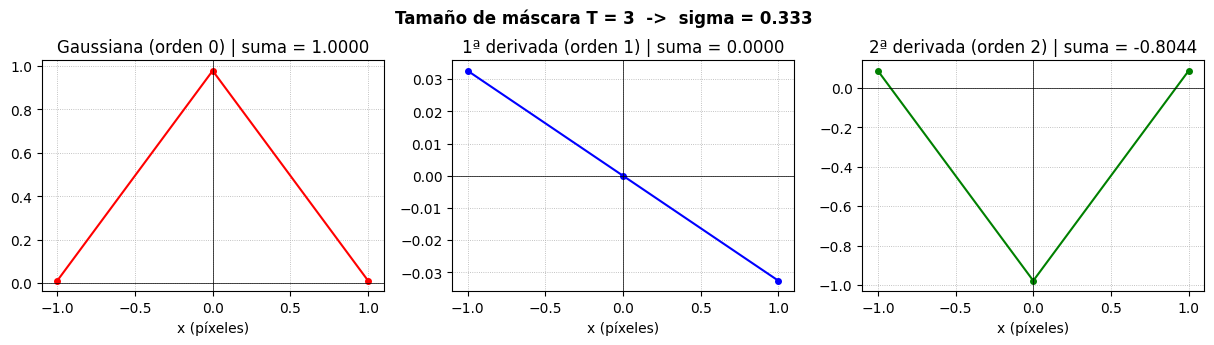

In [33]:
print('FIJAMOS PRIMERO EL TAMAÑO DE LA MÁSCARA')
show_by_size(3)  # T = 3

**$T=3$ ($\sigma = 0{,}33$).** Con solo tres muestras la forma apenas se reconoce. La Gaussiana es prácticamente $[0{,}01;\ 0{,}98;\ 0{,}01]$: en $x=\pm1$ la muestra vale $e^{-1/(2\sigma^2)} = e^{-4{,}5} \approx 0{,}011$ y en $x=0$ vale 1, así que al dividir por la suma ($1 + 2\cdot 0{,}011 = 1{,}022$) quedan $0{,}011/1{,}022 \approx 0{,}01$ a los lados y $1/1{,}022 \approx 0{,}98$ en el centro. Por eso casi no suaviza; la primera derivada tiene coeficientes de solo $\pm 0{,}03$, y la segunda es casi solo su valor central negativo. Es un muestreo insuficiente, igual que el caso $\sigma=0{,}25$ que se ve más abajo.

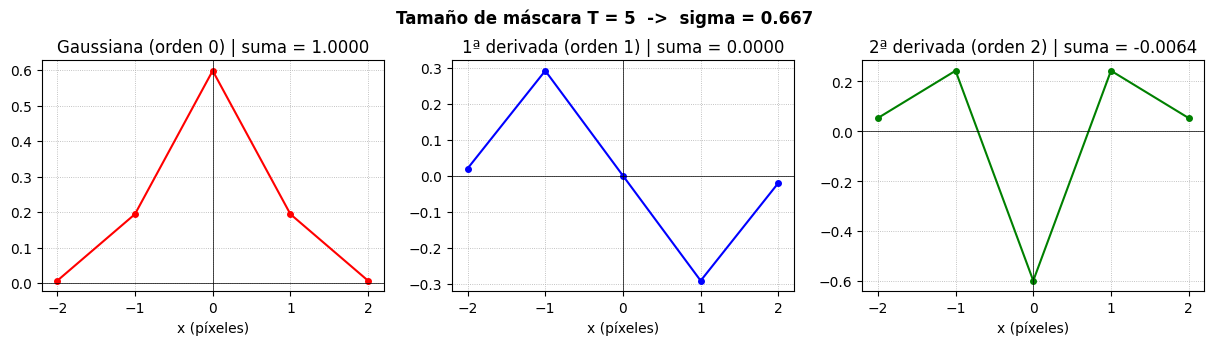

In [34]:
show_by_size(5)  # T = 5

**$T=5$ ($\sigma = 0{,}67$).** Con cinco muestras ya se reconocen la campana y los dos lóbulos de cada derivada, aunque de manera todavía grosera.

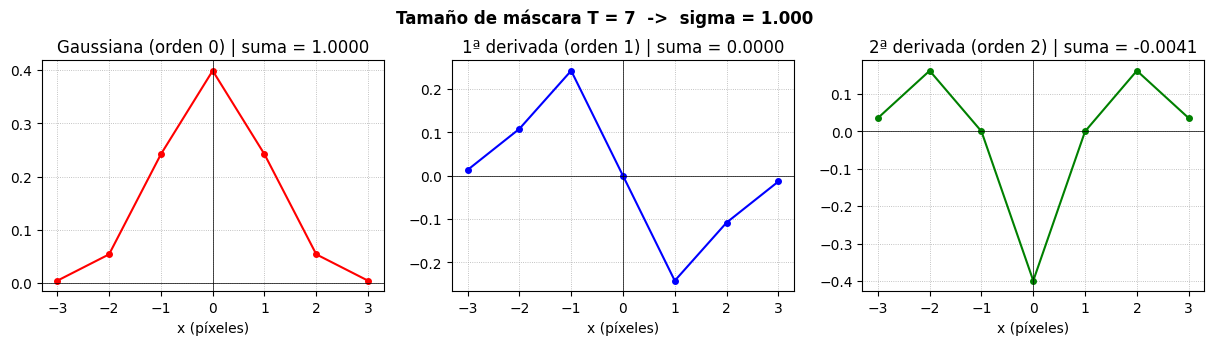

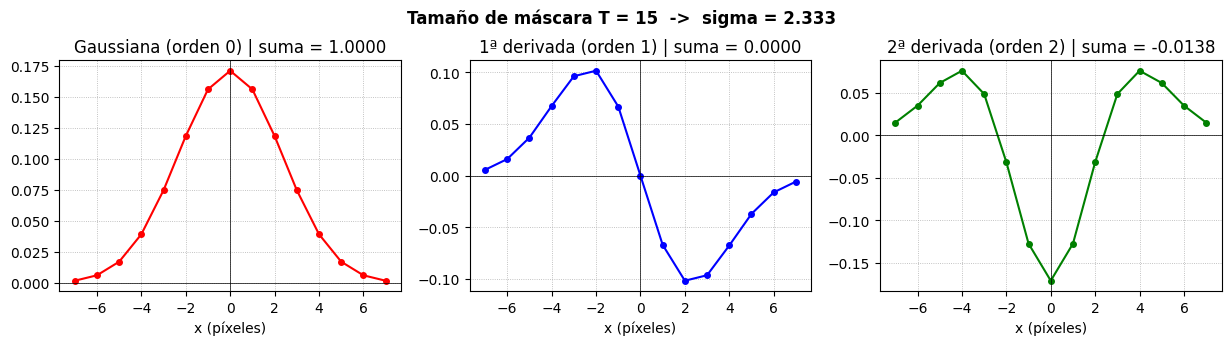

In [35]:
for sizeMask in [7, 15]:  # T = 7 y T = 15
    show_by_size(sizeMask)

**$T=7$ ($\sigma = 1$) y $T=15$ ($\sigma = 2{,}33$).** A partir de $T=7$ los perfiles ya se parecen a las curvas continuas de la figura de verificación.

FIJAMOS AHORA EL SIGMA


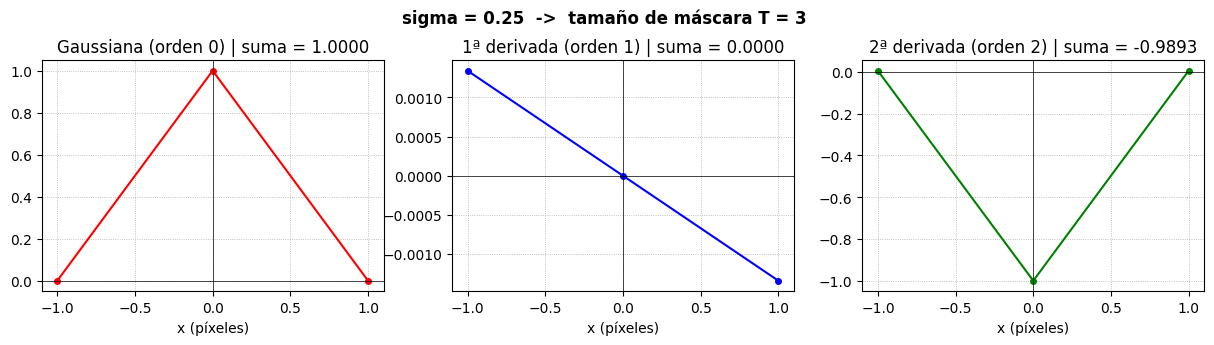

In [36]:
print('FIJAMOS AHORA EL SIGMA')
show_by_sigma(0.25)  # sigma = 0.25

**$\sigma = 0{,}25$ ($T=3$).** Es un muestreo insuficiente. En $x=\pm 1$ la Gaussiana vale $e^{-8} \approx 3\cdot10^{-4}$, así que la máscara de orden 0 es prácticamente $[0, 1, 0]$, es decir, no suaviza. La de orden 1 tiene coeficientes del orden de $10^{-3}$, prácticamente nula, y la de orden 2 es casi solo el valor central. Una Gaussiana con $\sigma$ menor que la separación entre píxeles no se puede representar con muestras enteras.

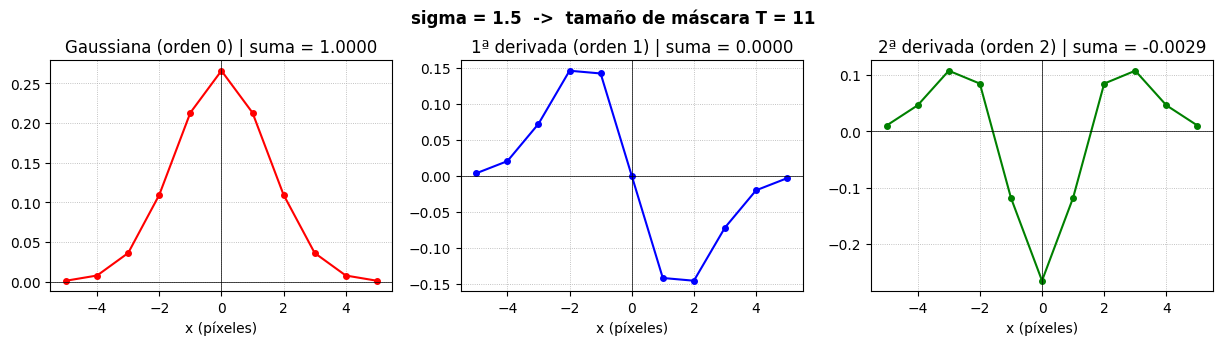

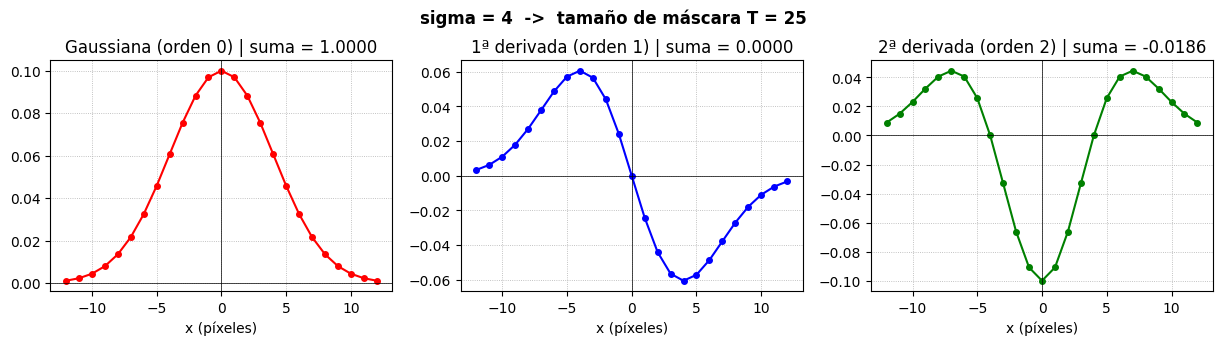

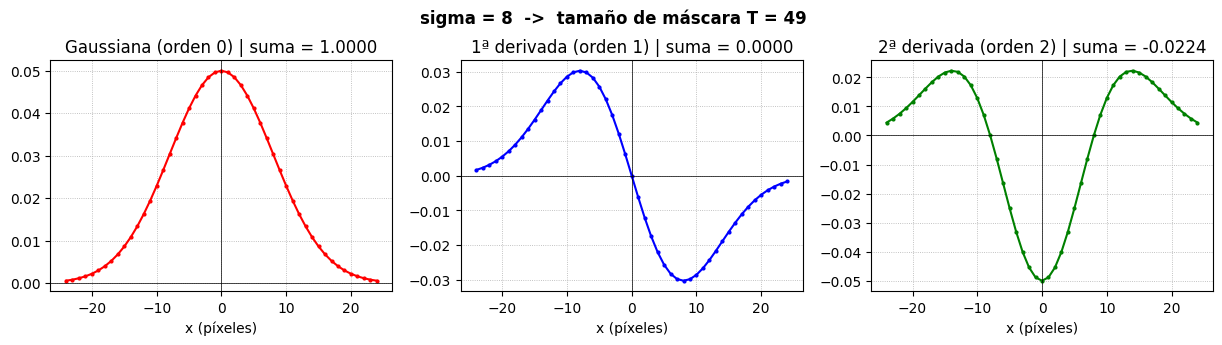

In [37]:
for sigma in [1.5, 4, 8]:  # sigma = 1.5, 4 y 8
    show_by_sigma(sigma)

**$\sigma = 1{,}5$, 4 y 8.** La forma coincide con la teórica en los tres casos. Al crecer $\sigma$ las curvas se ensanchan y bajan, porque la máscara tiene más coeficientes y la Gaussiana tiene que seguir sumando 1.

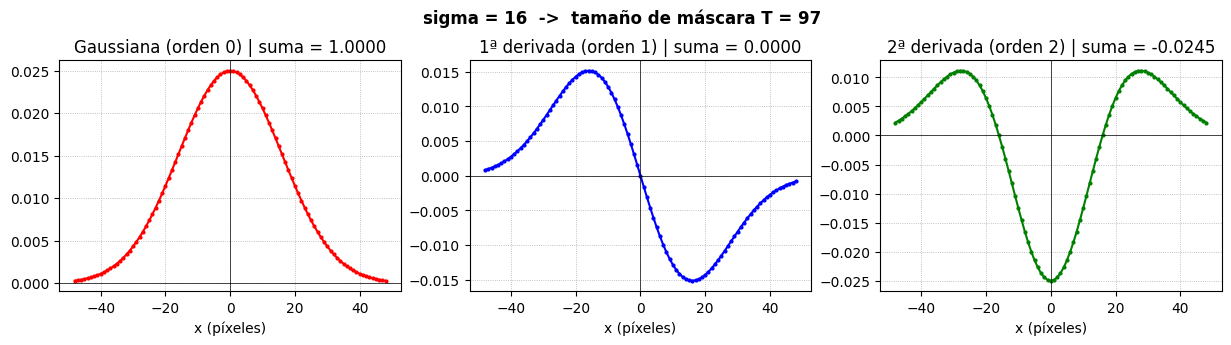

In [38]:
show_by_sigma(16)  # sigma = 16

**$\sigma = 16$ ($T=97$).** Es el caso más ancho: la forma sigue siendo la teórica, pero las curvas son muy bajas. El coeficiente central de la Gaussiana es solo 0,025, y el de la segunda derivada, -0,025.

### Análisis y discusión: discretización de kernels Gaussianos 1D

#### 1. ¿Tienen sentido las formas obtenidas?

Sí. Las tres coinciden con las curvas continuas de la figura de verificación con $\sigma=1$:

- **Orden 0.** Es una campana simétrica y positiva con el máximo en $x=0$: pesa más el píxel central y cada vez menos los alejados, que es lo que se espera de un filtro de suavizado (paso bajo). Al crecer $\sigma$ la campana se ensancha y baja, porque el área siempre suma 1. Por ejemplo, el coeficiente central pasa de 0,98 con $T=3$ a 0,40 con $T=7$. El coeficiente central es $g(0)=1$ dividido por la suma de todas las muestras:
  - $T=3$ ($\sigma=1/3$): en $x=\pm1$ la muestra vale $e^{-1/(2\sigma^2)} = e^{-4{,}5} \approx 0{,}011$, así que el central es $\dfrac{1}{1 + 2\cdot 0{,}011} \approx 0{,}98$.
  - $T=7$ ($\sigma=1$): las muestras en $x=\pm1, \pm2, \pm3$ valen $e^{-0{,}5} \approx 0{,}607$, $e^{-2} \approx 0{,}135$ y $e^{-4{,}5} \approx 0{,}011$, así que el central es $\dfrac{1}{1 + 2\,(0{,}607 + 0{,}135 + 0{,}011)} = \dfrac{1}{2{,}506} \approx 0{,}40$.
- **Orden 1.** Es una función impar: positiva a un lado del origen, negativa al otro, y cero en $x=0$. Los extremos están en $x=\pm\sigma$. Su forma es la de un detector de pendiente: sobre una zona de intensidad constante los dos lóbulos se cancelan, y sobre una rampa o un borde uno pesa más que el otro. Que el lóbulo positivo quede a la izquierda se debe al signo de $g'$. Al usarla para convolucionar, la máscara se voltea y la respuesta a un escalón ascendente es positiva.
- **Orden 2.** Es una función par con un mínimo negativo en el centro y dos lóbulos positivos a los lados, que cruzan el cero en $x=\pm\sigma$ (el "sombrero mexicano" invertido). Responde a la curvatura y se anula justo en el centro de un borde, donde la primera derivada es máxima. Esos cruces por cero son los que usa el detector de Marr-Hildreth.

Los casos que no se parecen a las curvas continuas ($T=3$, $T=5$ y $\sigma=0{,}25$) los comento debajo de su figura: con tan pocas muestras, o con $\sigma$ menor que la separación entre píxeles, la forma no se puede representar bien.

#### Experimento extra 1: suma de los coeficientes de cada máscara

Las diapositivas plantean dos preguntas: por qué las máscaras de derivada suman "aproximadamente" cero y no exactamente cero, y cuál de las dos sumas se acerca más a cero. Para responderlas con datos, calculo la suma de cada máscara para todos los casos del enunciado.

In [39]:
print(f"{'Entrada':>13s} | {'sigma':>6s} | {'T':>3s} | {'suma orden 0':>12s} | {'suma orden 1':>12s} | {'suma orden 2':>12s}")  # cabecera de la tabla
print('-' * 76)  # línea separadora
cases = [dict(sizeMask=T) for T in size_masks] + [dict(sigma=s) for s in sigma_values]  # casos a probar: primero por tamaño y luego por sigma
for case in cases:  # una fila por caso
    sums = [gaussianMask1D(order=o, **case).sum() for o in range(3)]  # suma de cada orden (**case pasa sigma o sizeMask)
    T = len(gaussianMask1D(order=0, **case))  # tamaño de la máscara
    sigma = case.get('sigma', (T - 1) / 6)  # sigma dada o calculada a partir de T
    label = f"T = {case['sizeMask']}" if 'sizeMask' in case else f"sigma = {case['sigma']}"  # texto de la primera columna
    print(f'{label:>13s} | {sigma:6.3f} | {T:3d} | {sums[0]:12.6f} | {sums[1]:12.1e} | {sums[2]:12.6f}')  # imprime la fila

# Límite teórico de la suma de orden 2 para sigma grande (efecto del truncamiento en 3*sigma)
print(f'\nLímite teórico de la suma de orden 2 por truncar en 3*sigma: {-6 * np.exp(-4.5) / np.sqrt(2 * np.pi):.4f}')  # valor al que tiende la suma de orden 2

      Entrada |  sigma |   T | suma orden 0 | suma orden 1 | suma orden 2
----------------------------------------------------------------------------
        T = 3 |  0.333 |   3 |     1.000000 |      0.0e+00 |    -0.804384
        T = 5 |  0.667 |   5 |     1.000000 |      1.0e-17 |    -0.006356
        T = 7 |  1.000 |   7 |     1.000000 |     -2.8e-17 |    -0.004088
       T = 15 |  2.333 |  15 |     1.000000 |      1.4e-17 |    -0.013847
 sigma = 0.25 |  0.250 |   3 |     1.000000 |      0.0e+00 |    -0.989272
  sigma = 1.5 |  1.500 |  11 |     1.000000 |     -2.0e-17 |    -0.002893
    sigma = 4 |  4.000 |  25 |     1.000000 |     -5.2e-18 |    -0.018590
    sigma = 8 |  8.000 |  49 |     1.000000 |     -5.2e-18 |    -0.022416
   sigma = 16 | 16.000 |  97 |     1.000000 |      8.0e-18 |    -0.024487

Límite teórico de la suma de orden 2 por truncar en 3*sigma: -0.0266


#### 2. ¿Por qué las derivadas suman (aproximadamente) cero y la Gaussiana uno?

- **Orden 0.** Divido por la suma, así que suma 1 por construcción. Es lo que debe ocurrir: al suavizar una zona de intensidad constante el valor no debe cambiar. Si la suma fuera distinta de 1, la imagen se aclararía u oscurecería en su conjunto.
- **Derivadas.** La derivada de una constante es 0, así que una máscara de derivada aplicada a una zona uniforme debe dar 0, y eso solo ocurre si sus coeficientes suman 0. En el continuo se cumple: $\int g' = 0$ y $\int g'' = 0$. Por eso no se pueden normalizar dividiendo por su suma: se dividiría por 0, o por un número minúsculo que dispararía los coeficientes.

La tabla anterior responde a la pregunta de las diapositivas: **la suma de la primera derivada está mucho más cerca de cero**, del orden de $10^{-17}$, que es simplemente el error de redondeo de coma flotante. La razón es la simetría: $g'$ es impar y la rejilla es simétrica, así que cada coeficiente $m(x)$ se cancela exactamente con $m(-x)$, se trunque donde se trunque.

La segunda derivada es par, así que no hay cancelación por simetría, y su suma solo es cero en el continuo integrando hasta $\pm\infty$. En la máscara discreta influyen dos efectos:

- **Truncamiento en $3\sigma$.** Más allá de $|x| > \sigma$, $g''$ es positiva, así que al cortar en $\pm 3\sigma$ se pierden dos "colas" positivas y la suma queda negativa. Lo que se pierde se puede calcular sin integrar a mano: el área bajo una segunda derivada es lo que cambia la primera derivada entre los dos extremos. Para una cola, de $3\sigma$ a $\infty$, eso es $g'(\infty) - g'(3\sigma) = -g'(3\sigma)$, que con la Gaussiana normalizada y el factor $\sigma^2$ vale $3e^{-4{,}5}/\sqrt{2\pi} \approx 0{,}013$. Con las dos colas, la suma tiende a $-0{,}027$ para $\sigma$ grande (es el límite teórico que imprime la celda del experimento), como se ve en la tabla, donde con $\sigma=8$ y $16$ se acerca a ese valor (-0,022 y -0,024).
- **Muestreo con $\sigma$ pequeño.** Con $T=3$ o $\sigma=0{,}25$ la suma se aleja mucho de 0 (de $-0{,}8$ a $-1$), porque la máscara se reduce prácticamente a su valor central negativo.

Por eso las diapositivas dicen "aproximadamente": la suma solo es exactamente cero en el continuo, y en la primera derivada lo es gracias a la simetría.

#### Experimento extra 2: ¿qué aporta la normalización de escala?

La pregunta 4 del enunciado pide explicar qué ocurre si no se normaliza; este experimento lo muestra con datos en lugar de solo con la teoría. Para comprobar el efecto de la normalización, convoluciono un escalón ideal de altura 1 con la máscara de primera derivada para $\sigma \in \{1{,}5;\ 4;\ 8;\ 16\}$, primero con la normalización por $\sigma$ y luego sin ella. El escalón es el modelo más sencillo de borde: un borde del mismo contraste debería producir la misma respuesta máxima con cualquier $\sigma$. Solo miro la zona central de la señal, lejos de sus extremos, para que el relleno con ceros de `np.convolve` no introduzca bordes falsos.

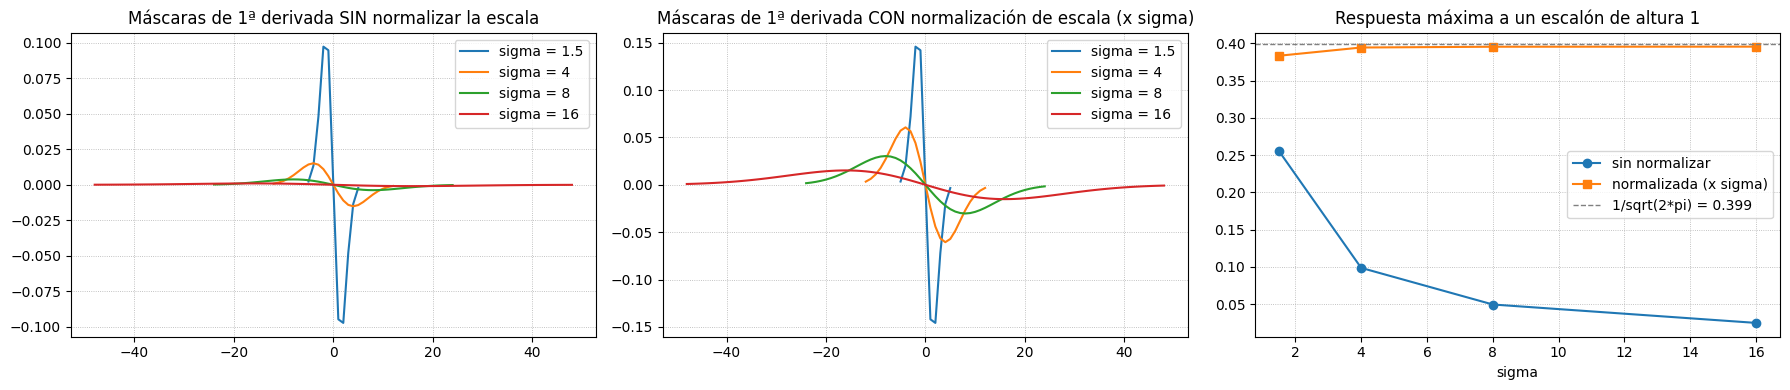

sigma =  1.5: respuesta máxima sin normalizar = 0.2557 | normalizada = 0.3835
sigma =    4: respuesta máxima sin normalizar = 0.0986 | normalizada = 0.3946
sigma =    8: respuesta máxima sin normalizar = 0.0495 | normalizada = 0.3956
sigma =   16: respuesta máxima sin normalizar = 0.0247 | normalizada = 0.3957


In [40]:
step = np.concatenate([np.zeros(200), np.ones(200)])   # escalón ideal de altura 1 en x = 200
sigmas_test = [1.5, 4, 8, 16]  # sigmas con las que se prueba
peak_norm, peak_raw = [], []  # respuestas máximas con y sin normalización

fig, axs = plt.subplots(1, 3, figsize=(18, 4))  # tres gráficas en una fila
for s in sigmas_test:  # para cada sigma
    m1 = gaussianMask1D(sigma=s, order=1)      # con normalización de escala
    m1_raw = m1 / s                            # la misma máscara sin multiplicar por sigma
    k = (len(m1) - 1) // 2  # radio de la máscara
    x = np.arange(-k, k + 1)  # posiciones de los coeficientes
    axs[0].plot(x, m1_raw, label=f'sigma = {s}')  # perfil sin normalizar
    axs[1].plot(x, m1, label=f'sigma = {s}')  # perfil normalizado
    # np.convolve hace convolución (voltea la máscara); el signo no importa porque miramos |respuesta|
    peak_norm.append(np.abs(np.convolve(step, m1, mode='same'))[100:300].max())  # máximo de |respuesta| lejos de los extremos del vector
    peak_raw.append(np.abs(np.convolve(step, m1_raw, mode='same'))[100:300].max())  # lo mismo con la máscara sin normalizar

axs[0].set_title('Máscaras de 1ª derivada SIN normalizar la escala')  # título de la gráfica 1
axs[1].set_title('Máscaras de 1ª derivada CON normalización de escala (x sigma)')  # título de la gráfica 2
axs[2].plot(sigmas_test, peak_raw, 'o-', label='sin normalizar')  # respuesta máxima sin normalizar frente a sigma
axs[2].plot(sigmas_test, peak_norm, 's-', label='normalizada (x sigma)')  # respuesta máxima normalizada frente a sigma
axs[2].axhline(1 / np.sqrt(2 * np.pi), color='gray', ls='--', lw=1, label='1/sqrt(2*pi) = 0.399')  # valor teórico
axs[2].set_title('Respuesta máxima a un escalón de altura 1')  # título de la gráfica 3
axs[2].set_xlabel('sigma')  # etiqueta del eje x
for ax in axs:  # para las tres gráficas
    ax.grid(True, linestyle=':', linewidth=0.6)  # cuadrícula punteada
    ax.legend()  # leyenda
plt.tight_layout()  # ajusta los márgenes
plt.show()  # muestra la figura

for s, pn, pr in zip(sigmas_test, peak_norm, peak_raw):  # recorre a la vez cada sigma y sus dos respuestas
    print(f'sigma = {s:4}: respuesta máxima sin normalizar = {pr:.4f} | normalizada = {pn:.4f}')  # imprime las dos respuestas

#### 3. ¿Cómo se normaliza cada orden y qué pasa si no se hace?

| Orden | Normalización | Efecto si no se aplica |
|---|---|---|
| 0 | Dividir por $\sum_i g(x_i)$ para que sume 1 | La suma de las muestras de $e^{-x^2/2\sigma^2}$ es $\approx \sigma\sqrt{2\pi}$: con $\sigma = 4$ valdría unos 10, y la imagen suavizada saldría 10 veces más brillante. Además el factor cambiaría con $\sigma$. |
| 1 | Multiplicar por $\sigma$ (y dividir por la misma constante del orden 0) | La respuesta a un borde decrece como $1/\sigma$ |
| 2 | Multiplicar por $\sigma^2$ (y dividir por la misma constante) | La respuesta decrece como $1/\sigma^2$ |

El motivo de la normalización de escala es este. La respuesta de la derivada de orden $n$ de una Gaussiana normalizada a un borde es proporcional a $1/\sigma^n$, porque cada derivada introduce un factor $1/\sigma$. Por tanto, cuanto más grande es la escala a la que se mira la imagen, más pequeña sale la respuesta, aunque el borde sea exactamente el mismo. Multiplicar por $\sigma^n$ compensa ese factor y hace que respuestas obtenidas con distintos $\sigma$ sean comparables.

El experimento anterior lo confirma numéricamente para la primera derivada:

- **Sin normalizar,** la respuesta máxima al mismo escalón cae de 0,26 ($\sigma=1{,}5$) a 0,025 ($\sigma=16$): se divide entre 2 cada vez que $\sigma$ se duplica, como predice el factor $1/\sigma$.
- **Con la normalización,** se queda prácticamente constante, en torno a 0,39-0,40, que es el valor teórico $1/\sqrt{2\pi} \approx 0{,}399$, es decir, $\sigma \cdot g_\sigma(0)$ de la Gaussiana normalizada. Con $\sigma=1{,}5$ sale algo menor (0,38) porque el muestreo con un $\sigma$ tan pequeño es más grosero.

Este resultado también justifica la decisión de dividir las derivadas por $\sum_i g(x_i)$. Sin esa división, el factor $\sigma\sqrt{2\pi}$ que arrastra la Gaussiana sin normalizar haría que la respuesta *creciera* proporcionalmente a $\sigma$, y la normalización de escala no conseguiría su objetivo.

Por último, las gráficas de perfiles muestran que, aun normalizadas, las máscaras de derivada se hacen más bajas y anchas al crecer $\sigma$, igual que la Gaussiana. Es lo esperado: lo que la normalización mantiene constante es la *respuesta* a una estructura de la escala correspondiente, no la altura de la máscara.

### Uso de IA generativa (Ejercicio 2)

- **Código:** el código de los apartados que pide el enunciado lo escribí yo a partir de las diapositivas de teoría (filtrado, Gaussianas y bordes), del material de la asignatura y de la documentación de OpenCV. Para los experimentos extra, miré en los libros de la asignatura y lo contrasté con Gemini (3.8 Flash) para ver lo que me comentaba.
- **Contraste con Gemini:** una vez hecho el ejercicio, usé Gemini para contrastar y reafirmar algunos conceptos: la normalización de escala de las derivadas, el $\sigma$ automático de `cv2.GaussianBlur` y el porqué de los resultados de la mediana. Lo que no coincidía con las diapositivas o con la documentación lo comprobé ahí antes de usarlo.
- **Revisión final con Claude:** contrastar explicaciones que había redactado para ver si estaba en lo correcto, contrastar resultados, asegurar experimentos extra.

---

### Lo que he aprendido

**Ejercicio 1: uso crítico de la IA generativa**

- Un LLM con búsqueda profunda da en minutos una visión general que a mano me habría costado horas, pero no se puede usar sin comprobar. Ninguna referencia era inventada, pero sí había errores en los detalles: una cifra que no aparece en el artículo, un factor mal calculado, un dato de capacidad presentado como consumo o un workshop presentado como conferencia. Solo los he detectado abriendo los PDF originales.
- Las cifras de consumo energético dependen mucho de cómo se obtienen: no es lo mismo una estimación que una medición, ni una GPU sola que un centro de datos con poco tráfico. Comparar números de estudios distintos sin mirar su metodología lleva a conclusiones engañosas.
- La búsqueda manual es más lenta, pero me da control sobre qué estoy leyendo. Lo más útil ha sido combinar las dos: el LLM para orientarme y la búsqueda manual y los artículos para comprobar.
- Del artículo del apartado B me quedo con que describir bien una imagen y razonar sobre ella son capacidades distintas: modelos que explican con soltura conceptos de física fallan al decidir si una torre se cae o al contar bloques.

**Ejercicio 2: ruido, filtrado y bordes**

- Cada tipo de ruido necesita su filtro: el Gaussiano funciona con ruido Gaussiano porque al promediar el ruido se compensa, y la mediana con sal y pimienta porque descarta los valores extremos sin emborronar los bordes.
- Filtrar siempre tiene un coste: cuanto más grande es la ventana, más ruido se quita pero más detalle se pierde. Con poco ruido ($\sigma=10$), según el PSNR, filtrar incluso empeora la imagen.
- La derivada amplifica el ruido, así que antes de detectar bordes conviene suavizar. Sobel ya lleva un pequeño suavizado incorporado, pero con ruido fuerte no basta.
- Mirar las imágenes no es suficiente: medir con el PSNR me ha permitido ver cosas que a simple vista no se aprecian, pero también que el PSNR no siempre coincide con lo que ve una persona.
- Al discretizar una Gaussiana hay que cuidar la normalización: la máscara de suavizado debe sumar 1, las de derivada deben sumar 0, y multiplicarlas por $\sigma$ o $\sigma^2$ hace que la respuesta a un borde no dependa de la escala. Lo he comprobado con el experimento del escalón.
- Revisar el código con datos me ha servido para encontrar errores que no se veían: una variable que funcionaba solo por existir fuera de la función y una normalización que hacía crecer la respuesta con $\sigma$.



### Feedback sobre la práctica

Me ha parecido una práctica muy completa. Los dos ejercicios se pueden resolver de forma básica, pero dejan mucho margen para ir más allá y entender el porqué de cada resultado, y eso es lo que más he aprovechado.

- **Ejercicio 1.** Comparar la búsqueda manual con la asistida por LLMs, y comprobar cada cifra en los artículos originales, me ha obligado a leer con más cuidado de lo que suelo hacer. Ha sido la parte que reafirma el hecho de que hay que contrastar toda la información que se recibe de una inteligencia artificial.
- **Ejercicio 2.** Más que aplicar los filtros, lo interesante ha sido preguntarme por qué cada uno se comporta como lo hace: por qué con poco ruido filtrar empeora la imagen, por qué la mediana borra los radios o por qué hace falta la normalización de escala. Para responderlo me han servido mucho las diapositivas y los libros de referencia de la asignatura, sobre todo Szeliski, donde he encontrado, por ejemplo, la definición del PSNR y la relación entre suavizar y derivar.
- Los experimentos extra que permite la práctica (la tabla de PSNR, las sumas de las máscaras o el experimento del escalón) han sido la mejor forma de comprobar con datos lo que se ve en clase, en lugar de quedarme solo con la explicación teórica.

### Bibliografía y fuentes consultadas

Las referencias de los artículos del Ejercicio 1 están en su propio apartado ("Referencias principales"). Aquí recojo el material que he usado para el Ejercicio 2 y para el trabajo en general.

**Diapositivas de la asignatura**

- Tema 1: *Introduction*.
- Tema 2.1: *Image Filtering* (tipos de ruido, convolución, filtros de suavizado, mediana y Sobel).
- Tema 2.2: *Gaussian Filters and Edges* (discretización de la Gaussiana, separabilidad, derivadas, Sobel, Laplaciano de Gaussiana y normalización de escala).
- Presentación de la Práctica 1 (*Assignment1.pdf*), en especial las indicaciones del ejercicio 2.B.

**Libros**

- R. Szeliski, *Computer Vision: Algorithms and Applications*, 2.ª ed., Springer, 2022. Apartados 2.3.3 (definición del MSE y del PSNR), 3.4.2 (eliminación de ruido y limitaciones del PSNR) y 7.2.1 (detección de bordes: suavizar y derivar).

**Documentación**

- Documentación oficial de OpenCV, módulo *imgproc*: `cv2.blur`, `cv2.GaussianBlur`, `cv2.getGaussianKernel` (cálculo automático de $\sigma$), `cv2.medianBlur`, `cv2.Sobel` y `cv2.magnitude`.

**Herramientas de IA (contraste)**

Se detallan al final de cada ejercicio.